# Miniproyecto 2: Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes

**Universidad de los Andes — Maestría en Inteligencia Artificial (MAIA)**  
**Curso:** Técnicas de Deep Learning (MAIA-4213)

### Autores
| Nombre Completo | Correo Electrónico | Código |
| :--- | :--- | :--- |
| **Otto Wilmer Castillo Santacruz** | `o.castillos@uniandes.edu.co` | 202611101 |
| **Edgar Andrés Pérez Mora** | `ea.perezm1@uniandes.edu.co` | 200822340 |
| **Silvio Yopasa Romero** | `s.yopasa@uniandes.edu.co` | 202615521 |

---

## Introducción y Contexto
Las reseñas y calificaciones de películas constituyen una fuente masiva de lenguaje natural a partir de la cual es posible inferir automáticamente la polaridad afectiva del autor (`positiva` o `negativa`) [3]. Abordar este problema de **clasificación binaria de sentimientos** tiene un alto impacto práctico en sistemas de recomendación personalizada para plataformas de *streaming*, monitoreo de recepción de audiencias y análisis de opinión en comercio electrónico. Sin embargo, clasificar textos extensos es complejo: los enfoques tradicionales de "bolsa de palabras" (*bag-of-words*), que cuentan la frecuencia de cada término ignorando su orden, fallan ante fenómenos secuenciales como las negaciones (*"not good"*), los contrastes adversativos (*"great cast, but a terrible script"*) o los cambios de tono entre la introducción y el cierre de una crítica.

En el estado del arte del aprendizaje profundo (*Deep Learning*), este desafío se resuelve combinando dos componentes complementarios:
1. **Representaciones vectoriales distribuidas (*word embeddings*):** Técnicas como Word2Vec y GloVe (*Global Vectors*) [4] transforman cada palabra discreta en un vector numérico denso de dimensión fija (p. ej. 100 números reales), de modo que palabras con significados o contextos similares queden cercanas en el espacio geométrico.
2. **Redes Neuronales Recurrentes (RNN) con compuertas:** Una RNN procesa la reseña palabra por palabra manteniendo una memoria interna denominada **estado oculto** (*hidden state*), que actualiza el contexto acumulado en cada paso temporal. Aunque las RNN simples sufren el problema del **desvanecimiento del gradiente** —la señal de aprendizaje se diluye exponencialmente al retropropagarse a través de cientos de palabras, impidiendo recordar el inicio del texto—, las arquitecturas con **compuertas** como **LSTM** (*Long Short-Term Memory*) [1] y **GRU** (*Gated Recurrent Unit*) [2] incorporan válvulas matemáticas aprendibles que deciden qué información conservar y cuál olvidar a lo largo de secuencias extensas.

En este trabajo se diseña, implementa y evalúa de extremo a extremo un flujo (*pipeline*) reproducible de procesamiento de lenguaje natural y aprendizaje profundo sobre el corpus de reseñas de IMDb [3]. El enfoque transforma el texto crudo en secuencias numéricas alineadas con *embeddings* preentrenados GloVe 6B [4], compara experimentalmente cinco variantes recurrentes (RNN simple, GRU [2], LSTM [1], BiLSTM y BiLSTM con ajuste fino [5]) combinadas con **agregación temporal global (*Concat Mean-Max Pooling*)** [5], y selecciona rigurosamente la arquitectura óptima sobre validación para evaluar su capacidad de generalización sobre un conjunto de prueba independiente.

### A. Objetivos
- **Objetivo general:** Desarrollar y validar un modelo basado en redes neuronales recurrentes (RNN, LSTM [1], GRU [2]) capaz de clasificar con alta exactitud y equilibrio entre clases las reseñas de películas de IMDb en las categorías `positiva` o `negativa`.
- **Objetivos específicos:**
  1. Construir un *pipeline* de limpieza, normalización, tokenización y codificación secuencial con *embeddings* preentrenados GloVe [4] libre de fuga de información entre particiones.
  2. Comparar experimentalmente bajo múltiples semillas el efecto del tipo de celda recurrente (RNN simple vs. GRU [2] vs. LSTM [1]), la bidireccionalidad y el ajuste fino (*fine-tuning*) de los *embeddings* [5].
  3. Evaluar cuantitativa y cualitativamente el modelo seleccionado en el conjunto de prueba mediante métricas de precisión, sensibilidad (*recall*), *F1-score*, curvas ROC/PR y análisis de interpretabilidad por oclusión de palabras.

### B. Conjunto de Datos
- Reseñas de películas de IMDb en inglés [3], etiquetadas con su polaridad (`0 = negativa`, `1 = positiva`), disponibles públicamente en Kaggle: [IMDb Movie Ratings Sentiment Analysis](https://www.kaggle.com/datasets/yasserh/imdb-movie-ratings-sentiment-analysis/data). El archivo `data/movie.csv` contiene $40\,000$ reseñas en dos columnas: `text` (texto de la reseña) y `label` (sentimiento).

### C. Actividades
1. **Preprocesamiento de las reseñas:** construir un *pipeline* que limpie y tokenice las reseñas y las convierta en secuencias numéricas utilizando *embeddings* preentrenados (GloVe [4]).
2. **Desarrollo de la arquitectura de red neuronal recurrente:** implementar una arquitectura recurrente (RNN, LSTM [1] o GRU [2]) con capa de *embedding*, capa recurrente, mecanismo de resumen temporal (*pooling* [5]), regularización (`Dropout`) y capa densa de salida con activación sigmoide, justificando la elección de cada componente.
3. **Entrenamiento y evaluación del modelo:** dividir el conjunto de datos en entrenamiento (`Train`), validación (`Val`) y prueba (`Test`); seleccionar y entrenar el modelo con `Train` y `Val` mediante optimización adaptativa y detención temprana, y evaluar su desempeño final en `Test` reportando *precision*, *recall* y *F1-score*.

---
## 0. Configuración del Entorno e Importación de Librerías
Se importan las librerías requeridas para la manipulación y limpieza de texto, la tokenización (`nltk`), la partición estratificada de datos y el análisis estadístico de términos (`scikit-learn`), el diseño y entrenamiento de redes neuronales en PyTorch y la visualización. Asimismo, se fijan las semillas pseudoaleatorias para garantizar la reproducibilidad experimental y se configura el dispositivo de aceleración por hardware (`cuda`, `mps` o `cpu`).

In [1]:
# Importación de librerías, fijación de semillas y configuración del dispositivo
import copy
import hashlib
import json
import random
import re
import subprocess
import time
import unicodedata
import urllib.request
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from nltk.tokenize import RegexpTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

RANDOM_STATE = 42

def set_all_seeds(seed: int = RANDOM_STATE) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_all_seeds(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

sns.set_style("whitegrid")
print(f"PyTorch {torch.__version__} | Dispositivo: {DEVICE}")

PyTorch 2.15.0 | Dispositivo: mps


---
## 1. Preparación de las Reseñas para el Entrenamiento y Prueba del Modelo
En esta etapa se estructura el flujo de ingestión, exploración y preprocesamiento de las reseñas. El orden de las etapas responde a dos principios: (i) los pasos que **no aprenden nada de los datos** (depuración de duplicados, limpieza y tokenización) pueden aplicarse a todo el conjunto, mientras que (ii) los pasos que **sí aprenden de los datos** (vocabulario, longitud máxima de secuencia y matriz de *embeddings*) se ajustan exclusivamente con `Train`, después de la partición, para evitar la fuga de información (*data leakage*) hacia `Val` y `Test`.

### 1.1. Carga del Conjunto de Datos
Se lee el archivo `data/movie.csv`, se revisa su estructura, los tipos de datos y las etiquetas presentes, y se añade el nombre legible de cada clase (`0 = negativa`, `1 = positiva`). El archivo inicia con una marca de orden de bytes (BOM), por lo que se lee con la codificación `utf-8-sig` para que la primera columna se identifique correctamente como `text`.

In [ ]:
# Carga del conjunto de datos
DATA_PATH = Path("./data/movie.csv")

LABEL_NAMES = {0: "negativa", 1: "positiva"}
CLASSES = list(LABEL_NAMES.values())
CLASS_COLORS = {"negativa": "#C44E52", "positiva": "#4C72B0"}

df_reviews = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df_reviews["label_name"] = df_reviews["label"].map(LABEL_NAMES)

print(f"Dimensiones: {df_reviews.shape}")
display(df_reviews.head())
df_reviews.info()


Dimensiones: (40000, 3)


,text,label,label_name
0,I grew up (b. 1965) watching and loving the Th...,0,negativa
1,"When I put this movie in my DVD player, and sa...",0,negativa
2,Why do people who do not know what a particula...,0,negativa
3,Even though I have great interest in Biblical ...,0,negativa
4,Im a die hard Dads Army fan and nothing will e...,1,positiva


<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   text        40000 non-null  str  
 1   label       40000 non-null  int64
 2   label_name  40000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 937.6 KB


### 1.2. Análisis Exploratorio de Datos (EDA)
En primer lugar, se identifican y eliminan los registros nulos, vacíos y las reseñas duplicadas, de modo que todas las estadísticas posteriores describan exactamente el conjunto que se empleará para entrenar y evaluar el modelo. Sobre el conjunto depurado se analiza la distribución de clases, la longitud de las reseñas y el ruido presente en el texto. El análisis del vocabulario se realiza en la sección 1.4.2, ya que requiere el texto limpio y tokenizado y debe calcularse únicamente sobre `Train`.

#### 1.2.1. Eliminación de registros nulos, vacíos y reseñas duplicadas
Se verifica la presencia de valores nulos, reseñas vacías, textos duplicados y filas completamente duplicadas. Además de las copias exactas, se buscan duplicados tras una normalización ligera (eliminación de etiquetas HTML, conversión a minúsculas y unificación de espacios), que detecta reseñas idénticas con diferencias de formato. Se conserva una sola copia por grupo y se descartan por completo los grupos cuyas copias tengan etiquetas contradictorias. El `DataFrame` resultante (`df_clean`) es la base para el resto del EDA, la partición (1.3) y el *pipeline* de preprocesamiento (1.4), y evita que una misma reseña quede simultáneamente en entrenamiento y prueba.

In [3]:
# Detección y eliminación de registros nulos, vacíos y reseñas duplicadas
def normalize_for_dedup(text: str) -> str:
    # Normalización ligera solo para comparar reseñas: sin etiquetas HTML, en minúsculas y con espacios unificados
    return " ".join(re.sub(r"</?[a-zA-Z][^<>]*>", " ", text).lower().split())

print("Valores nulos:")
print(df_reviews.isna().sum())
n_empty = df_reviews["text"].fillna("").str.strip().eq("").sum()
print(f"\nReseñas vacías: {n_empty}")
print(f"Textos duplicados (copias exactas): {df_reviews['text'].duplicated().sum()}")
print(f"Filas totalmente duplicadas: {df_reviews.duplicated().sum()}")

df_valid = df_reviews.dropna(subset=["text", "label"])
df_valid = df_valid[df_valid["text"].str.strip().ne("")].copy()
df_valid["text_norm"] = df_valid["text"].map(normalize_for_dedup)

labels_per_text = df_valid.groupby("text_norm")["label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
is_redundant_copy = df_valid["text_norm"].duplicated()
print(f"Textos duplicados tras normalizar: {is_redundant_copy.sum()} "
      f"| Grupos con etiquetas contradictorias: {len(conflicting_texts)}")
print("Copias redundantes por clase:")
print(df_valid.loc[is_redundant_copy, "label_name"].value_counts().reindex(CLASSES, fill_value=0))

df_clean = (df_valid[~df_valid["text_norm"].isin(conflicting_texts)]
            .drop_duplicates("text_norm")
            .drop(columns="text_norm")
            .reset_index(drop=True))
print(f"\nReseñas: {len(df_reviews)} originales -> {len(df_clean)} únicas "
      f"({len(df_reviews) - len(df_clean)} descartadas)")

Valores nulos:
text          0
label         0
label_name    0
dtype: int64

Reseñas vacías: 0
Textos duplicados (copias exactas): 277
Filas totalmente duplicadas: 277
Textos duplicados tras normalizar: 278 | Grupos con etiquetas contradictorias: 0
Copias redundantes por clase:
label_name
negativa    205
positiva     73
Name: count, dtype: int64

Reseñas: 40000 originales -> 39722 únicas (278 descartadas)


#### 1.2.2. Distribución de frecuencias absolutas y relativas por clase de sentimiento
Se cuantifica el número de reseñas positivas y negativas en el conjunto depurado, en valores absolutos y en porcentaje, y se calcula la razón de desbalance (clase mayoritaria / minoritaria). Este resultado determina si es necesario ponderar la función de pérdida y si la exactitud (*accuracy*) es una métrica informativa por sí sola.

,frecuencia_absoluta,frecuencia_relativa_%
label_name,,
negativa,19814,49.88
positiva,19908,50.12


Clase mayoritaria: positiva (19908)
Clase minoritaria: negativa (19814)
Razón de desbalance (mayoritaria / minoritaria): 1.005


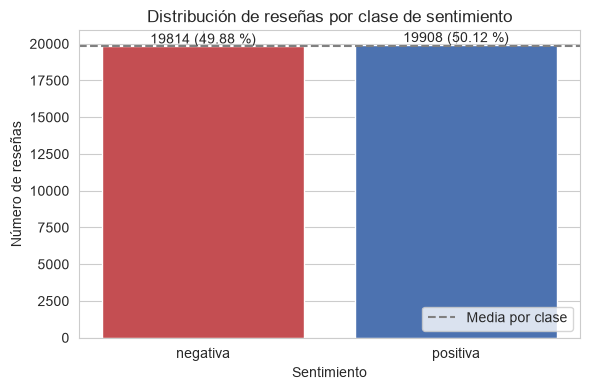

In [4]:
# Distribución de frecuencias absolutas y relativas por clase de sentimiento
class_counts = df_clean["label_name"].value_counts().reindex(CLASSES)
df_distribution = pd.DataFrame({
    "frecuencia_absoluta": class_counts,
    "frecuencia_relativa_%": (class_counts / class_counts.sum() * 100).round(2)
})
display(df_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Clase mayoritaria: {class_counts.idxmax()} ({class_counts.max()})")
print(f"Clase minoritaria: {class_counts.idxmin()} ({class_counts.min()})")
print(f"Razón de desbalance (mayoritaria / minoritaria): {imbalance_ratio:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_counts.index, class_counts.values, color=[CLASS_COLORS[c] for c in class_counts.index])
ax.axhline(class_counts.mean(), color="gray", linestyle="--", label="Media por clase")
for i, (count, pct) in enumerate(zip(class_counts, df_distribution["frecuencia_relativa_%"])):
    ax.text(i, count, f"{count} ({pct} %)", ha="center", va="bottom")
ax.set(xlabel="Sentimiento", ylabel="Número de reseñas", title="Distribución de reseñas por clase de sentimiento")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### 1.2.3. Distribución de la longitud de las reseñas por clase
Se calcula la longitud de cada reseña en caracteres y en palabras (sin contar las etiquetas HTML) y se reportan sus estadísticos descriptivos por clase, incluyendo los percentiles 90, 95 y 99, complementados con un histograma y un diagrama de caja por clase. El objetivo es dimensionar la longitud de las secuencias que deberá procesar la RNN y verificar que la longitud no varía sistemáticamente entre clases, lo que podría convertirse en un atajo para el modelo. Este análisis es descriptivo: la longitud máxima de secuencia (`MAX_LEN`) se fija en la sección 1.4.3 a partir del número de *tokens* de `Train` tras la limpieza.

Longitud en palabras:


,count,mean,std,min,50%,90%,95%,99%,max
negativa,19814.0,227.0,162.7,4.0,173.0,432.0,565.0,874.9,1491.0
positiva,19908.0,231.4,176.2,12.0,171.0,464.0,602.0,914.9,2459.0
total,39722.0,229.2,169.6,4.0,172.0,448.0,585.0,894.0,2459.0


Longitud en caracteres:


,count,mean,std,min,50%,90%,95%,99%,max
negativa,19814.0,1293.2,943.0,32.0,973.0,2479.7,3258.0,5041.7,8969.0
positiva,19908.0,1329.1,1033.0,65.0,973.0,2691.0,3498.6,5312.9,13704.0
total,39722.0,1311.2,989.3,32.0,973.0,2585.0,3390.0,5171.0,13704.0


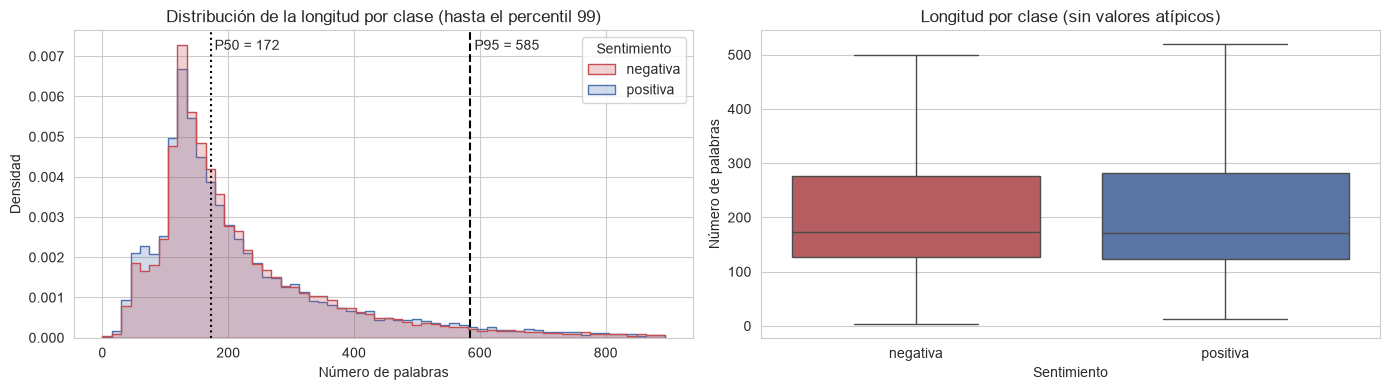

In [5]:
# Estadísticos descriptivos e histogramas de la longitud de las reseñas por clase
PERCENTILES = [0.5, 0.9, 0.95, 0.99]
df_clean["n_caracteres"] = df_clean["text"].str.len()
df_clean["n_palabras"] = df_clean["text"].map(normalize_for_dedup).str.split().str.len()

def length_summary(column: str) -> pd.DataFrame:
    by_class = df_clean.groupby("label_name")[column].describe(percentiles=PERCENTILES).reindex(CLASSES)
    overall = df_clean[column].describe(percentiles=PERCENTILES).to_frame("total").T
    return pd.concat([by_class, overall]).round(1)

print("Longitud en palabras:")
display(length_summary("n_palabras"))
print("Longitud en caracteres:")
display(length_summary("n_caracteres"))

# El histograma se limita al percentil 99 para que la cola larga no oculte la forma de la distribución
p99_words = df_clean["n_palabras"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df_clean, x="n_palabras", hue="label_name", hue_order=CLASSES, palette=CLASS_COLORS,
             bins=60, binrange=(0, p99_words), element="step", stat="density", common_norm=False, ax=axes[0])
sns.move_legend(axes[0], "upper right", title="Sentimiento")
for q, style in [(0.5, ":"), (0.95, "--")]:
    x = df_clean["n_palabras"].quantile(q)
    axes[0].axvline(x, color="black", linestyle=style)
    axes[0].text(x, axes[0].get_ylim()[1] * 0.97, f" P{int(q * 100)} = {x:.0f}", va="top")
axes[0].set(title="Distribución de la longitud por clase (hasta el percentil 99)",
            xlabel="Número de palabras", ylabel="Densidad")
sns.boxplot(data=df_clean, x="label_name", y="n_palabras", hue="label_name", order=CLASSES,
            palette=CLASS_COLORS, showfliers=False, legend=False, ax=axes[1])
axes[1].set(title="Longitud por clase (sin valores atípicos)", xlabel="Sentimiento", ylabel="Número de palabras")
plt.tight_layout()
plt.show()

#### 1.2.4. Inspección de ejemplos y ruido en el texto
Se muestran, con semilla fija para garantizar la reproducibilidad, dos reseñas de cada clase y se cuantifica, por clase, el porcentaje de reseñas que contienen elementos que deben tratarse en la limpieza: etiquetas HTML (p. ej. `<br />`), URLs, calificaciones numéricas explícitas (p. ej. `7/10`), contracciones (p. ej. *don't*), apóstrofos tipográficos (`’`) y caracteres no ASCII. Finalmente, se listan los caracteres no ASCII más frecuentes para definir su normalización.

In [6]:
# Visualización de reseñas de ejemplo por clase y cuantificación de ruido en el texto
N_EXAMPLES_PER_CLASS = 2
MAX_CHARS_SHOWN = 500

for cls_name in CLASSES:
    cls_subset = df_clean[df_clean["label_name"] == cls_name]
    sample = cls_subset.sample(min(N_EXAMPLES_PER_CLASS, len(cls_subset)), random_state=RANDOM_STATE)
    for text in sample["text"]:
        print(f"[{cls_name}] {text[:MAX_CHARS_SHOWN]}{'...' if len(text) > MAX_CHARS_SHOWN else ''}\n")

NOISE_PATTERNS = {
    "Etiquetas HTML": r"</?[a-zA-Z][^<>]*>",
    "URLs": r"https?://\S+|www\.\S+",
    "Calificaciones numéricas (x/10)": r"\b\d+(?:\.\d+)?\s*/\s*10\b",
    "Contracciones (n't, 's, 're...)": r"[a-z]['’](?:t|s|re|ve|ll|d|m)\b",
    "Apóstrofos tipográficos (’ ‘ ` ´)": r"[’‘`´\x91\x92]",
    "Caracteres no ASCII": r"[^\x00-\x7f]",
}
df_noise = pd.DataFrame({
    name: df_clean.groupby("label_name")["text"]
                  .apply(lambda s: s.str.contains(pattern, case=False, regex=True).mean() * 100)
                  .reindex(CLASSES)
    for name, pattern in NOISE_PATTERNS.items()
}).T
df_noise["total"] = [df_clean["text"].str.contains(p, case=False, regex=True).mean() * 100
                     for p in NOISE_PATTERNS.values()]
print("Porcentaje de reseñas que contienen cada elemento:")
display(df_noise.round(2))

# Se muestra la representación del carácter y su código, ya que los caracteres de control de Windows-1252
# (p. ej. \x85, \x96, \x97) no son visibles e incluso pueden romper el formato de la tabla
non_ascii_counts = Counter(ch for text in df_clean["text"] for ch in text if ord(ch) > 127)
print("Caracteres no ASCII más frecuentes:")
display(pd.DataFrame([{
    "caracter": repr(ch),
    "código": f"U+{ord(ch):04X}",
    "nombre Unicode": unicodedata.name(ch, "control C1 (Windows-1252)"),
    "ocurrencias": count,
} for ch, count in non_ascii_counts.most_common(15)]))

[negativa] this fourth installment of the series is the last to get a theatrical release,though it feels like a direct to video movie.it's OK,i guess,but nothing special.the acting is the worst of seen in the series up to this point.and like the third movie,there isn't much in the way of imagination.also,the sentence "directed by Alan Smithee" is never a good thing.Smithee is the pseudonym directors use when they want nothing to do with the movie.anyway,its an acceptable movie in the Hellraiser series,but ...

[negativa] I guess I was prepared after all the years of hearing about it. First heard about it from Siskel and Ebert. When they said Divine ate excrement, I had to look it up. Then a friend told me about it in 1991. She said also that her parents saw it when it first came out and that her mom almost dumped her dad over it! So by the time I caught Pink Flamingos on Sundance today, I was prepared. For the most part.<br /><br />I still couldn't help but be surprised by the anal clo

label_name,negativa,positiva,total
Etiquetas HTML,59.64,57.25,58.44
URLs,0.32,0.43,0.38
Calificaciones numéricas (x/10),5.42,6.61,6.02
"Contracciones (n't, 's, 're...)",88.74,85.13,86.93
Apóstrofos tipográficos (’ ‘ ` ´),1.25,1.26,1.26
Caracteres no ASCII,10.17,8.52,9.35


Caracteres no ASCII más frecuentes:


,caracter,código,nombre Unicode,ocurrencias
0,'é',U+00E9,LATIN SMALL LETTER E WITH ACUTE,2657
1,'\x96',U+0096,control C1 (Windows-1252),1917
2,'\x85',U+0085,control C1 (Windows-1252),1142
3,'\x97',U+0097,control C1 (Windows-1252),476
4,'´',U+00B4,ACUTE ACCENT,339
5,'’',U+2019,RIGHT SINGLE QUOTATION MARK,201
6,'á',U+00E1,LATIN SMALL LETTER A WITH ACUTE,178
7,'è',U+00E8,LATIN SMALL LETTER E WITH GRAVE,125
8,'ö',U+00F6,LATIN SMALL LETTER O WITH DIAERESIS,123
9,'–',U+2013,EN DASH,119


#### 1.2.5. Hallazgos del EDA

Todas las cifras corresponden al conjunto depurado ($39\,722$ reseñas únicas), salvo las de duplicados.

- **Registros nulos y duplicados:** el archivo contiene $40\,000$ reseñas sin valores nulos ni reseñas vacías. Se identificaron 277 copias exactas y una adicional que solo difiere en formato (278 en total), concentradas en `negativa` (205 frente a 73). Ninguna copia aparece con etiquetas contradictorias. Se conserva una sola reseña por grupo antes de cualquier análisis o partición, evitando que copias de una misma reseña queden simultáneamente en entrenamiento y prueba (*data leakage*).
- **Balance de clases:** el conjunto está prácticamente balanceado, con $19\,814$ reseñas negativas (49.88 %) y $19\,908$ positivas (50.12 %), y una razón de desbalance de 1.005. Por lo tanto, no es necesario ponderar la función de pérdida y la exactitud es una métrica informativa, aunque se reportan también *precision*, *recall* y *F1-score*, como exige el enunciado.
- **Longitud de las reseñas:** la distribución es asimétrica a la derecha, con una mediana de 172 palabras, una media de 229.2 (σ = 169.6) y una cola larga (percentil 95 = 585, percentil 99 = 894, máximo = $2\,459$). Las distribuciones de ambas clases son muy similares (medianas de 173 y 171 palabras; medias de 227.0 y 231.4), por lo que la longitud no constituye un atajo para distinguir el sentimiento. La cola larga obliga a truncar las secuencias: procesar las reseñas completas sería costoso para una RNN, cuyo cómputo es secuencial, y agravaría la dificultad de propagar el gradiente a lo largo de secuencias muy largas.
- **Ruido en el texto:** el 58.44 % de las reseñas contiene etiquetas HTML (principalmente `<br />`) y el 86.93 % contracciones (p. ej. *don't*, *isn't*). El 9.35 % contiene caracteres no ASCII, que corresponden a letras acentuadas en nombres propios (p. ej. `é`) y a caracteres de control de Windows-1252 (`\x96`, `\x85`, `\x97`) que en el texto original funcionan como guiones o puntos suspensivos; el 1.26 % usa apóstrofos tipográficos (`´`, `’`). Las URLs son marginales (0.38 %). El 6.02 % de las reseñas incluye calificaciones explícitas del tipo *x/10*, algo más frecuentes en las positivas (6.61 % frente a 5.42 %). La incidencia del ruido es similar en ambas clases, de modo que no introduce un sesgo evidente.
- **Implicaciones para el preprocesamiento:** (i) eliminar las etiquetas HTML y las URLs antes de tokenizar, para que `<br />` no se convierta en el *token* `br`; (ii) unificar los apóstrofos antes de expandir las contracciones, para preservar negaciones como *not*; (iii) reemplazar por un espacio, y no eliminar, los caracteres no ASCII residuales, para no unir las palabras que separan; (iv) conservar los números y el signo `/`, que forman las calificaciones explícitas; (v) fijar `MAX_LEN` a partir de la longitud en *tokens* de `Train` (sección 1.4.3); y (vi) entrenar sin pesos por clase.

### 1.3. Partición en Conjuntos de Entrenamiento, Validación y Prueba
El conjunto de datos depurado se divide de forma estratificada en los subconjuntos de entrenamiento (`Train`, 70 %), validación (`Val`, 15 %) y prueba (`Test`, 15 %), preservando la proporción de reseñas positivas y negativas. Se verifica que ninguna reseña (comparada tras la normalización de la sección 1.2.1) aparezca en más de una partición y que la proporción de cada clase se mantenga en las tres particiones. La partición se realiza **antes** de construir el vocabulario, fijar `MAX_LEN` y construir la matriz de *embeddings*, de modo que estos artefactos se ajusten exclusivamente con `Train`.

Cada partición cumple un papel distinto y exclusivo (el protocolo completo se detalla en la sección 2.3):
- **`Train`** ajusta los pesos de la red y los artefactos del preprocesamiento (vocabulario, `MAX_LEN` y matriz de *embeddings*).
- **`Val`** sustenta todas las decisiones de modelado: la época del mejor *checkpoint*, la detención temprana (*early stopping*) y la selección de la configuración final.
- **`Test`** se reserva para una **única** evaluación del modelo final, de modo que sus métricas sean una estimación no sesgada de la capacidad de generalización.

In [7]:
# Partición estratificada en conjuntos de entrenamiento, validación y prueba
VAL_SIZE = 0.15
TEST_SIZE = 0.15

df_train_val, df_test = train_test_split(
    df_clean, test_size=TEST_SIZE, stratify=df_clean["label"], random_state=RANDOM_STATE)
df_train, df_val = train_test_split(
    df_train_val, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=df_train_val["label"], random_state=RANDOM_STATE)
df_train, df_val, df_test = (df.reset_index(drop=True) for df in (df_train, df_val, df_test))
splits = {"Train": df_train, "Val": df_val, "Test": df_test}

# Verificación de ausencia de fuga de información entre particiones
normalized_texts = {name: set(df["text"].map(normalize_for_dedup)) for name, df in splits.items()}
assert normalized_texts["Train"].isdisjoint(normalized_texts["Val"])
assert normalized_texts["Train"].isdisjoint(normalized_texts["Test"])
assert normalized_texts["Val"].isdisjoint(normalized_texts["Test"])

# Verificación de la estratificación: proporción de cada clase en el total y en cada partición
split_counts = pd.DataFrame({name: df["label_name"].value_counts() for name, df in splits.items()}).reindex(CLASSES)
split_pct = pd.DataFrame({
    "Total_%": df_clean["label_name"].value_counts(normalize=True),
    **{f"{name}_%": df["label_name"].value_counts(normalize=True) for name, df in splits.items()}
}).reindex(CLASSES).mul(100).round(2)
display(pd.concat([split_counts, split_pct], axis=1))
print(" | ".join(f"{name}: {len(df)} ({len(df) / len(df_clean) * 100:.1f} %)" for name, df in splits.items()))

,Train,Val,Test,Total_%,Train_%,Val_%,Test_%
label_name,,,,,,,
negativa,13869,2973,2972,49.88,49.88,49.89,49.87
positiva,13935,2986,2987,50.12,50.12,50.11,50.13


Train: 27804 (70.0 %) | Val: 5959 (15.0 %) | Test: 5959 (15.0 %)


### 1.4. Pipeline de Preprocesamiento: Limpieza, Tokenización, Vocabulario y *Embeddings*
Se construye el *pipeline* que transforma cada reseña en una secuencia de índices enteros apta para la capa de *embedding* de la red recurrente. El orden de los pasos no es arbitrario: cada uno depende de que el anterior haya dejado el texto en la forma esperada.

| # | Paso | Ajustado con | Razón de su posición |
| :-: | :--- | :--- | :--- |
| 1 | Eliminación de etiquetas HTML y URLs | — | Debe ir primero: de lo contrario el tokenizador convierte `<br />` en el *token* `br` y fragmenta las URLs. |
| 2 | Normalización de caracteres (apóstrofos tipográficos → `'`, acentos → ASCII, demás caracteres no ASCII → espacio) | — | Antes de expandir contracciones: *don’t* con apóstrofo tipográfico no coincidiría con los patrones de contracción. Los caracteres no ASCII se reemplazan por espacio y no se eliminan, porque varios (p. ej. guiones de Windows-1252) separan palabras. |
| 3 | Conversión a minúsculas | — | Antes de expandir contracciones (patrones en minúsculas) y porque GloVe 6B es un vocabulario sin mayúsculas [4]. |
| 4 | Expansión de contracciones (*don't* → *do not*) | — | Antes de tokenizar: el tokenizador separaría *don't* en `don` y `t`, y la negación `not` desaparecería. |
| 5 | Tokenización (`[a-z0-9]+` y los signos `!`, `?`, `/`) | — | Último paso sin estado: descarta la puntuación restante y conserva números y calificaciones como `7 / 10`. |
| 6 | Construcción del vocabulario (`MIN_FREQ`) | `Train` | Requiere el texto tokenizado y debe ajustarse solo con `Train`. |
| 7 | Codificación, truncado y relleno (`MAX_LEN`) | `Train` | Requiere el vocabulario; `MAX_LEN` se fija con la longitud en *tokens* de `Train`. |
| 8 | Matriz de *embeddings* preentrenados | `Train` | Requiere el vocabulario: cada fila corresponde a un índice. |
| 9 | `Dataset` y `DataLoader` | — | Empaqueta las secuencias, longitudes y etiquetas para el entrenamiento. |

Deliberadamente **no** se aplican tres pasos habituales en representaciones de bolsa de palabras:
- **Eliminación de palabras vacías (*stopwords*):** la lista en inglés de `nltk` incluye *not*, *no*, *nor*, *don't* o *isn't*; eliminarlas convertiría *\"not good\"* en *\"good\"* e invertiría la polaridad. La RNN aprende por sí misma a restar peso a las palabras de función a partir de su contexto.
- ***Stemming* o lematización:** produce raíces (p. ej. `movi`, `act`) que no existen en el vocabulario de GloVe, lo que reduciría la cobertura de los *embeddings* preentrenados.
- **Eliminación de números:** las calificaciones explícitas (p. ej. *\"3/10\"*, *\"10/10\"*) son una señal directa del sentimiento.

#### 1.4.1. Limpieza, normalización y tokenización del texto
Se implementan los pasos 1 a 5 como funciones independientes y se muestra su efecto paso a paso sobre una reseña de `Train` que contiene etiquetas HTML y contracciones, junto con una tabla que compara el texto original con el procesado. Como estos pasos no aprenden nada de los datos, se aplican por igual a las tres particiones. Finalmente, se verifica cuantitativamente el efecto del orden: se cuentan en `Train` los *tokens* espurios (`br`, `t`, `s`, `don`, `isn`, `didn`) y las ocurrencias de `not` que produce un tokenizador ingenuo (minúsculas y separación por caracteres alfanuméricos, sin limpieza previa) frente al *pipeline* propuesto.

In [8]:
# Definición de las funciones de limpieza, normalización y tokenización
HTML_TAG_RE = re.compile(r"</?[a-zA-Z][^<>]*>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
APOSTROPHE_RE = re.compile(r"[’‘`´\x91\x92]")
NON_ASCII_RE = re.compile(r"[^\x00-\x7f]")
# Contracciones irregulares y formas con 's que equivalen a "is"; el resto de 's se trata como posesivo
SPECIAL_CONTRACTIONS = {
    r"\bwon't\b": "will not", r"\bcan't\b": "can not", r"\bshan't\b": "shall not",
    r"\bain't\b": "is not", r"\blet's\b": "let us",
    r"\b(it|that|there|here|what|who|where|he|she)'s\b": r"\1 is",
}
SUFFIX_CONTRACTIONS = {
    r"(?:n't|'nt)\b": " not", r"'re\b": " are", r"'ve\b": " have", r"'ll\b": " will",
    r"'d\b": " would", r"'m\b": " am", r"'s\b": "",
}
TOKEN_PATTERN = r"[a-z0-9]+|[!?/]"
tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def remove_html_and_urls(text: str) -> str:
    return URL_RE.sub(" ", HTML_TAG_RE.sub(" ", text))

def normalize_characters(text: str) -> str:
    text = APOSTROPHE_RE.sub("'", text)
    # NFKD descompone los caracteres acentuados (é -> e + tilde) y se descartan las marcas diacríticas
    text = "".join(ch for ch in unicodedata.normalize("NFKD", text) if not unicodedata.combining(ch))
    # El resto de caracteres no ASCII (p. ej. guiones y puntos suspensivos de Windows-1252) se reemplaza
    # por un espacio para no unir las palabras que separan
    return NON_ASCII_RE.sub(" ", text)

def expand_contractions(text: str) -> str:
    for pattern, replacement in {**SPECIAL_CONTRACTIONS, **SUFFIX_CONTRACTIONS}.items():
        text = re.sub(pattern, replacement, text)
    return text

def clean_text(text: str) -> str:
    text = remove_html_and_urls(text)
    text = normalize_characters(text)
    text = text.lower()
    return expand_contractions(text)

def tokenize(text: str) -> list:
    return tokenizer.tokenize(clean_text(text))

# Efecto paso a paso sobre una reseña de Train con etiquetas HTML y contracciones
has_noise = df_train["text"].str.contains("<br") & df_train["text"].str.contains(r"n't\b")
sample_text = (df_train.loc[has_noise, "text"] if has_noise.any() else df_train["text"]).iloc[0]
steps = [("Texto original", sample_text)]
steps.append(("1. Sin HTML ni URLs", remove_html_and_urls(steps[-1][1])))
steps.append(("2. Caracteres normalizados", normalize_characters(steps[-1][1])))
steps.append(("3. Minúsculas", steps[-1][1].lower()))
steps.append(("4. Contracciones expandidas", expand_contractions(steps[-1][1])))
steps.append(("5. Tokens", " | ".join(tokenizer.tokenize(steps[-1][1]))))
for name, text in steps:
    print(f"{name}:\n{text[:MAX_CHARS_SHOWN]}{'...' if len(text) > MAX_CHARS_SHOWN else ''}\n")

Texto original:
I must have seen this movie about four or five times already, and it gets better with each viewing. Suffice it to say: This is the best film I've ever seen. And I think I've seen a lot.<br /><br />But I've always wondered why this film got so shunned in some reviews or ratings. For example, take the IMDb Top 250. Why does it rank only at #216 (as of today)? Surely, the answer's not in the film itself (because that is nothing but flawless), but in its reception. The film caused controversy in its...

1. Sin HTML ni URLs:
I must have seen this movie about four or five times already, and it gets better with each viewing. Suffice it to say: This is the best film I've ever seen. And I think I've seen a lot.  But I've always wondered why this film got so shunned in some reviews or ratings. For example, take the IMDb Top 250. Why does it rank only at #216 (as of today)? Surely, the answer's not in the film itself (because that is nothing but flawless), but in its reception. Th

In [9]:
# Aplicación del pipeline a las tres particiones y comparación del texto original con el procesado
for df in splits.values():
    df["tokens"] = df["text"].map(tokenize)

processed_sample = " ".join(tokenize(sample_text))
display(pd.DataFrame({
    "etapa": ["Texto original", "Texto procesado"],
    "caracteres": [len(sample_text), len(processed_sample)],
    "palabras / tokens": [len(sample_text.split()), len(processed_sample.split())],
    "texto": [sample_text[:300], processed_sample[:300]],
}))

# Verificación del orden: tokens espurios y negaciones con un tokenizador ingenuo frente al pipeline propuesto
naive_tokenizer = RegexpTokenizer(r"[a-z0-9]+")
naive_counts = Counter(t for text in df_train["text"] for t in naive_tokenizer.tokenize(text.lower()))
pipeline_counts = Counter(t for tokens in df_train["tokens"] for t in tokens)
check_tokens = ["br", "t", "s", "don", "isn", "didn", "not"]
display(pd.DataFrame({
    "tokenizador ingenuo": [naive_counts[t] for t in check_tokens],
    "pipeline propuesto": [pipeline_counts[t] for t in check_tokens],
}, index=pd.Index(check_tokens, name="token")))

n_empty_tokens = sum(int(df["tokens"].map(len).eq(0).sum()) for df in splits.values())
print(f"Reseñas que quedan vacías tras la limpieza: {n_empty_tokens}")

,etapa,caracteres,palabras / tokens,texto
0,Texto original,1717,296,I must have seen this movie about four or five...
1,Texto procesado,1647,313,i must have seen this movie about four or five...


,tokenizador ingenuo,pipeline propuesto
token,,
br,112258,3
t,38403,842
s,70274,961
don,9826,347
isn,3575,0
didn,4838,2
not,33958,71540


Reseñas que quedan vacías tras la limpieza: 0


#### 1.4.2. Análisis del vocabulario y construcción del vocabulario sobre `Train`
A partir de los *tokens* de `Train` se analiza la distribución estadística del vocabulario mediante tres conceptos fundamentales del Procesamiento del Lenguaje Natural (PLN):
- **Ley de Zipf y cobertura acumulada:** en cualquier corpus de lenguaje natural, unas pocas palabras muy frecuentes concentran la gran mayoría de las apariciones, mientras existe una "cola larga" de miles de palabras raras.
- ***Hapax legomena* (términos de aparición única):** palabras que aparecen una sola vez en todo `Train` (suelen corresponder a errores tipográficos, nombres propios muy específicos o palabras unidas por accidente). Incluirlas inflaría la memoria del modelo sin aportar capacidad de generalización, pues la red no puede aprender un patrón estadístico confiable a partir de un único ejemplo.
- **Ponderación TF-IDF (*Term Frequency – Inverse Document Frequency*):** medida estadística que cuantifica cuán representativa es una palabra para una clase, multiplicando su frecuencia en una reseña (*TF*) por un factor que penaliza las palabras genéricas presentes en casi todos los documentos (*IDF*). Como verificación cualitativa, se identifican los términos con mayor diferencia de peso TF-IDF medio entre reseñas positivas y negativas.

Con base en este análisis se construye el vocabulario conservando únicamente las palabras de `Train` que aparecen al menos `MIN_FREQ = 5` veces. Se reservan dos índices especiales al inicio de la tabla: `<pad> = 0` (*padding* o relleno para igualar longitudes) y `<unk> = 1` (*unknown*, asignado a cualquier palabra fuera del vocabulario o **OOV**, *Out-Of-Vocabulary*), reportando la tasa de OOV en cada partición.

,términos
Sin limpieza (minúsculas y alfanuméricos),79889
Con limpieza completa,79611
Con limpieza y MIN_FREQ = 5,30729


Hapax legomena: 29823 (37.5 % del vocabulario, 0.45 % de las ocurrencias)
Cobertura de las ocurrencias de Train con MIN_FREQ = 5: 98.77 %


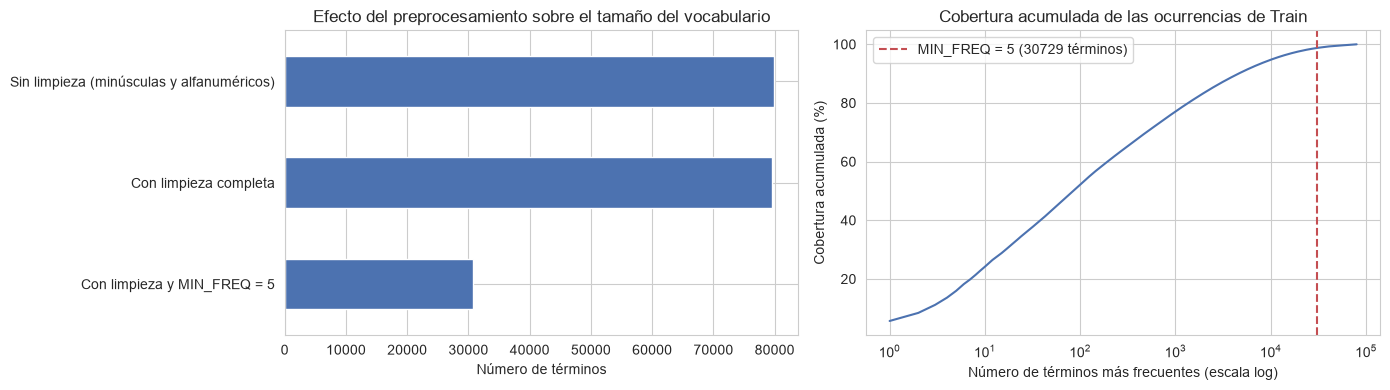

In [10]:
# Tamaño del vocabulario por etapa de preprocesamiento, hapax legomena y curva de cobertura acumulada
MIN_FREQ = 5

token_counts = pipeline_counts  # frecuencias de los tokens de Train calculadas en la sección 1.4.1
total_occurrences = sum(token_counts.values())
freqs = np.array(sorted(token_counts.values(), reverse=True))
cumulative_coverage = np.cumsum(freqs) / total_occurrences * 100
n_frequent = int((freqs >= MIN_FREQ).sum())

vocab_sizes = pd.Series({
    "Sin limpieza (minúsculas y alfanuméricos)": len(naive_counts),
    "Con limpieza completa": len(token_counts),
    f"Con limpieza y MIN_FREQ = {MIN_FREQ}": n_frequent,
}, name="términos")
display(vocab_sizes.to_frame())
n_hapax = int((freqs == 1).sum())
print(f"Hapax legomena: {n_hapax} ({n_hapax / len(freqs) * 100:.1f} % del vocabulario, "
      f"{n_hapax / total_occurrences * 100:.2f} % de las ocurrencias)")
print(f"Cobertura de las ocurrencias de Train con MIN_FREQ = {MIN_FREQ}: {cumulative_coverage[n_frequent - 1]:.2f} %")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vocab_sizes.plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set(title="Efecto del preprocesamiento sobre el tamaño del vocabulario", xlabel="Número de términos")
axes[0].invert_yaxis()
axes[1].plot(np.arange(1, len(freqs) + 1), cumulative_coverage, color="#4C72B0")
axes[1].axvline(n_frequent, color="#C44E52", linestyle="--", label=f"MIN_FREQ = {MIN_FREQ} ({n_frequent} términos)")
axes[1].set(xscale="log", title="Cobertura acumulada de las ocurrencias de Train",
            xlabel="Número de términos más frecuentes (escala log)", ylabel="Cobertura acumulada (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

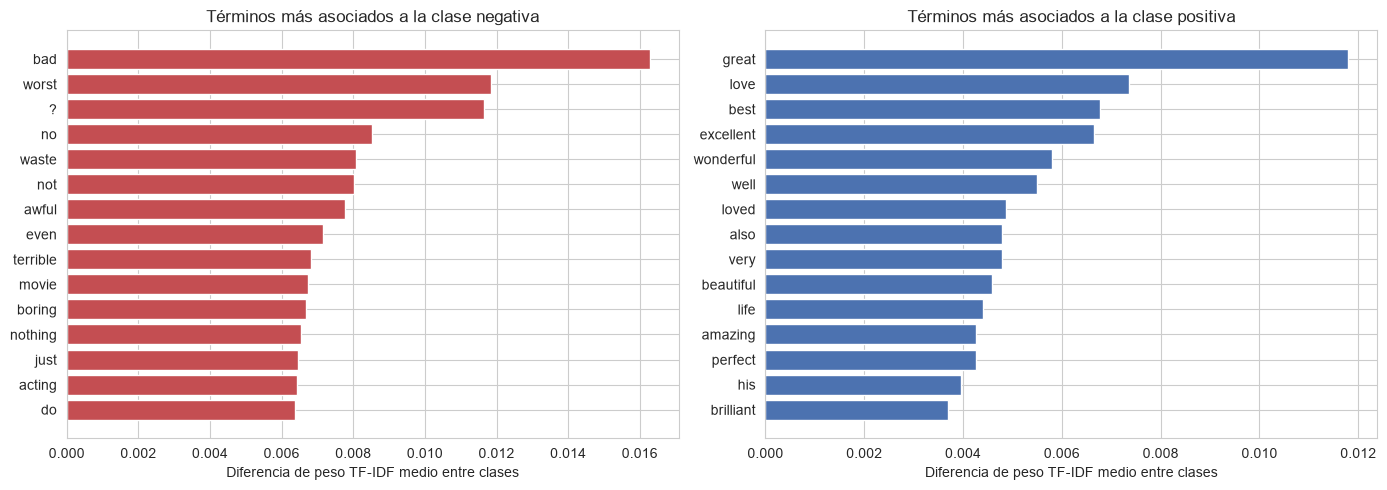

In [11]:
# Términos con mayor diferencia de peso TF-IDF medio entre clases (verificación cualitativa sobre Train)
N_TOP_TERMS = 15
tfidf = TfidfVectorizer(analyzer=lambda tokens: tokens, min_df=MIN_FREQ, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(df_train["tokens"])
feature_names = tfidf.get_feature_names_out()
is_positive = df_train["label"].to_numpy() == 1
mean_diff = (np.asarray(X_train_tfidf[is_positive].mean(axis=0)).ravel()
             - np.asarray(X_train_tfidf[~is_positive].mean(axis=0)).ravel())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls_name, idx in [(axes[0], "negativa", np.argsort(mean_diff)[:N_TOP_TERMS]),
                          (axes[1], "positiva", np.argsort(mean_diff)[::-1][:N_TOP_TERMS])]:
    ax.barh(feature_names[idx][::-1], np.abs(mean_diff[idx])[::-1], color=CLASS_COLORS[cls_name])
    ax.set(title=f"Términos más asociados a la clase {cls_name}",
           xlabel="Diferencia de peso TF-IDF medio entre clases")
plt.tight_layout()
plt.show()

In [12]:
# Construcción del vocabulario sobre Train y tasa de palabras fuera del vocabulario (OOV)
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1

itos = [PAD_TOKEN, UNK_TOKEN] + [token for token, count in token_counts.most_common() if count >= MIN_FREQ]
stoi = {token: idx for idx, token in enumerate(itos)}
VOCAB_SIZE = len(itos)
print(f"Tamaño del vocabulario (incluye {PAD_TOKEN} y {UNK_TOKEN}): {VOCAB_SIZE}")

oov_rates = {}
for name, df in splits.items():
    n_tokens = int(df["tokens"].map(len).sum())
    n_oov = sum(token not in stoi for tokens in df["tokens"] for token in tokens)
    oov_rates[name] = {"tokens": n_tokens, "tokens OOV": n_oov, "tasa_OOV_%": round(n_oov / n_tokens * 100, 2)}
display(pd.DataFrame(oov_rates).T)

Tamaño del vocabulario (incluye <pad> y <unk>): 30731


,tokens,tokens OOV,tasa_OOV_%
Train,6600020.0,81133.0,1.23
Val,1407407.0,22215.0,1.58
Test,1385244.0,21197.0,1.53


#### 1.4.3. Codificación numérica, truncado y relleno de secuencias
Se analiza la longitud en *tokens* de las reseñas de `Train` y, para varios valores candidatos de `MAX_LEN`, el porcentaje de reseñas que se truncarían y el porcentaje de *tokens* que se conservarían. Con base en ello se fija `MAX_LEN = 400`, buscando un equilibrio entre la información semántica conservada y el costo computacional, que en una red recurrente crece linealmente con el número de pasos temporales.

Cada reseña se convierte en una secuencia de índices enteros del vocabulario (`<unk>` para las palabras fuera de él). Las reseñas más largas que `MAX_LEN` se truncan aplicando la estrategia `tail` (conservar los **últimos** `MAX_LEN` *tokens*), dado que en las críticas cinematográficas los primeros párrafos suelen resumir la sinopsis de la trama mientras el párrafo final concentra el veredicto valorativo del autor. Las secuencias más cortas se rellenan con `<pad>` **al final** hasta alcanzar una matriz rectangular, pero se registra la longitud real de cada reseña para empaquetarla durante el paso hacia adelante (`pack_padded_sequence`), una operación de PyTorch que instruye a la celda recurrente para detener el cómputo exactamente en la última palabra real de cada reseña e ignorar por completo los *tokens* de relleno.

In [13]:
# Análisis de la longitud en tokens de Train para definir MAX_LEN
MAX_LEN_CANDIDATES = [100, 200, 300, 400, 500, 600, 800]
train_token_lengths = df_train["tokens"].map(len)
display(train_token_lengths.describe(percentiles=PERCENTILES).round(1).to_frame("tokens por reseña (Train)").T)
display(pd.DataFrame([{
    "MAX_LEN": max_len,
    "reseñas truncadas_%": round((train_token_lengths > max_len).mean() * 100, 2),
    "tokens conservados_%": round(train_token_lengths.clip(upper=max_len).sum() / train_token_lengths.sum() * 100, 2),
} for max_len in MAX_LEN_CANDIDATES]).set_index("MAX_LEN"))

,count,mean,std,min,50%,90%,95%,99%,max
tokens por reseña (Train),27804.0,237.4,175.1,8.0,179.0,464.0,605.0,928.0,2281.0


,reseñas truncadas_%,tokens conservados_%
MAX_LEN,,
100,88.29,40.63
200,42.73,67.79
300,23.33,81.13
400,13.61,88.71
500,8.31,93.24
600,5.10,96.03
800,1.99,98.83


In [14]:
# Codificación de reseñas en índices, truncado/relleno a MAX_LEN y registro de longitudes reales
MAX_LEN = 400
TRUNCATION = "tail"  # "tail" conserva los últimos MAX_LEN tokens; "head" conserva los primeros

def encode(tokens: list, max_len: int = MAX_LEN, truncation: str = TRUNCATION) -> tuple:
    ids = [stoi.get(token, UNK_IDX) for token in tokens] or [UNK_IDX]
    ids = ids[-max_len:] if truncation == "tail" else ids[:max_len]
    return ids + [PAD_IDX] * (max_len - len(ids)), len(ids)

encoded = {}
for name, df in splits.items():
    sequences, lengths = zip(*df["tokens"].map(encode))
    encoded[name] = {"sequences": np.array(sequences, dtype=np.int64),
                     "lengths": np.array(lengths, dtype=np.int64),
                     "labels": df["label"].to_numpy(dtype=np.float32)}
    print(f"{name}: secuencias {encoded[name]['sequences'].shape} | "
          f"truncadas: {(df['tokens'].map(len) > MAX_LEN).mean() * 100:.2f} %")

# Verificación: reconstrucción del texto a partir de los índices de una reseña de Train
example_ids, example_len = encoded["Train"]["sequences"][0], int(encoded["Train"]["lengths"][0])
example_tokens = df_train["tokens"][0][-MAX_LEN:] if TRUNCATION == "tail" else df_train["tokens"][0][:MAX_LEN]
n_show = min(25, example_len)
print(f"\nTokens originales (primeros {n_show}): {example_tokens[:n_show]}")
print(f"Índices (primeros {n_show}):           {example_ids[:n_show].tolist()}")
print(f"Reconstrucción (primeros {n_show}):    {[itos[i] for i in example_ids[:n_show]]}")
print(f"Longitud real: {example_len} | Relleno: {MAX_LEN - example_len} posiciones con índice {PAD_IDX}")

Train: secuencias (27804, 400) | truncadas: 13.61 %
Val: secuencias (5959, 400) | truncadas: 13.91 %
Test: secuencias (5959, 400) | truncadas: 12.89 %

Tokens originales (primeros 25): ['this', 'is', 'the', 'worst', 'film', 'i', 'have', 'ever', 'seen', 'and', 'what', 'disappoints', 'me', 'the', 'most', 'is', 'that', 'this', 'is', 'yash', 'raj', 'film', 'so', 'at', 'first']
Índices (primeros 25):           [11, 6, 2, 240, 20, 10, 24, 125, 111, 3, 49, 12001, 74, 2, 92, 6, 12, 11, 6, 15056, 6523, 20, 37, 30, 91]
Reconstrucción (primeros 25):    ['this', 'is', 'the', 'worst', 'film', 'i', 'have', 'ever', 'seen', 'and', 'what', 'disappoints', 'me', 'the', 'most', 'is', 'that', 'this', 'is', 'yash', 'raj', 'film', 'so', 'at', 'first']
Longitud real: 148 | Relleno: 252 posiciones con índice 0


#### 1.4.4. Construcción de la matriz de *embeddings* preentrenados
Se emplean los vectores preentrenados **GloVe 6B de dimensión 100** (*Global Vectors for Word Representation*) [4], entrenados sobre un corpus de 6 mil millones de palabras (Wikipedia y Gigaword) con un vocabulario de $400\,000$ términos en minúsculas, coherente con la normalización aplicada en la sección 1.4.1. Un *embedding* representa cada palabra mediante un vector de 100 coordenadas continuas aprendidas a partir de las estadísticas globales de coocurrencia (qué palabras suelen aparecer cerca de otras). Si el archivo no se encuentra en `data/glove/`, se descarga automáticamente del repositorio oficial de Stanford NLP en Hugging Face (≈ 822 MB) y se extrae únicamente el archivo de 100 dimensiones.

Se construye la matriz de *embeddings* de dimensión `VOCAB_SIZE × EMBED_DIM` ($30\,731 \times 100$) alineada con el vocabulario de `Train` siguiendo cuatro reglas de inicialización:
1. **Palabras presentes en GloVe:** copian directamente su vector preentrenado de 100 dimensiones.
2. **Palabras del vocabulario sin vector preentrenado:** se inicializan aleatoriamente con una distribución normal $\mathcal{N}(0, \sigma_{\text{GloVe}}^2)$ que preserva la escala estadística de los vectores GloVe.
3. **Token de palabra desconocida (`<unk>`, índice 1):** se inicializa con el **vector promedio (`glove_mean`)** de todos los vectores GloVe del vocabulario (el centroide semántico del espacio vectorial), evitando que la aparición de múltiples términos OOV en inferencia inyecte un mismo vector aleatorio con dirección arbitraria.
4. **Token de relleno (`<pad>`, índice 0):** se fija estrictamente en el vector nulo ($\vec{0}$) para que no aporte señal numérica.

Se reporta la cobertura del vocabulario (porcentaje de términos y de ocurrencias de `Train` con vector preentrenado), las palabras frecuentes sin vector y, como verificación cualitativa, los vecinos más cercanos de palabras clave mediante **similitud coseno** ($1.00$ indica dirección idéntica y $0.00$ ortogonalidad).

In [29]:
# Descarga (si es necesario) y carga de los vectores GloVe
EMBED_DIM = 100
GLOVE_DIR = Path("./data/glove") if Path("./data").exists() else Path("./microproyecto_2/data/glove")
GLOVE_PATH = GLOVE_DIR / f"glove.6B.{EMBED_DIM}d.txt"
GLOVE_URL = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"

if not GLOVE_PATH.exists():
    GLOVE_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = GLOVE_DIR / "glove.6B.zip"
    print(f"Descargando {GLOVE_URL} (≈ 822 MB)...")
    urllib.request.urlretrieve(GLOVE_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extract(GLOVE_PATH.name, GLOVE_DIR)
    zip_path.unlink()

# Solo se cargan los vectores de las palabras del vocabulario de Train (excluyendo tokens especiales)
glove_vectors = {}
with open(GLOVE_PATH, encoding="utf-8") as f:
    for line in f:
        word, values = line.split(" ", 1)
        if word in stoi and word not in (PAD_TOKEN, UNK_TOKEN):
            glove_vectors[word] = np.asarray(values.split(), dtype=np.float32)


In [16]:
# Construcción de la matriz de embeddings y cobertura del vocabulario
rng = np.random.default_rng(RANDOM_STATE)
glove_stack = np.stack(list(glove_vectors.values()))
glove_mean = glove_stack.mean(axis=0)
glove_std = glove_stack.std()
embedding_matrix = rng.normal(0, glove_std, size=(VOCAB_SIZE, EMBED_DIM)).astype(np.float32)
for word, vector in glove_vectors.items():
    embedding_matrix[stoi[word]] = vector
embedding_matrix[PAD_IDX] = 0.0
embedding_matrix[UNK_IDX] = glove_mean
EMBEDDING_MATRIX = torch.from_numpy(embedding_matrix)

vocab_words = itos[2:]
covered_words = sum(w in glove_vectors for w in vocab_words)
covered_occurrences = sum(token_counts[w] for w in vocab_words if w in glove_vectors)
vocab_occurrences = sum(token_counts[w] for w in vocab_words)
print(f"Matriz de embeddings: {tuple(EMBEDDING_MATRIX.shape)}")
print(f"Cobertura de términos del vocabulario: {covered_words / len(vocab_words) * 100:.2f} %")
print(f"Cobertura de ocurrencias en Train: {covered_occurrences / vocab_occurrences * 100:.2f} %")

missing_words = [(w, token_counts[w]) for w in vocab_words if w not in glove_vectors]
print("\nPalabras más frecuentes sin vector preentrenado:")
display(pd.DataFrame(missing_words[:15], columns=["palabra", "ocurrencias en Train"]))

# Verificación cualitativa: vecinos más cercanos (similitud coseno) dentro del vocabulario
QUERY_WORDS = [w for w in ["good", "bad", "not", "boring", "masterpiece"] if w in stoi]
normalized = embedding_matrix / np.maximum(np.linalg.norm(embedding_matrix, axis=1, keepdims=True), 1e-8)
neighbors = {}
for word in QUERY_WORDS:
    similarities = normalized @ normalized[stoi[word]]
    nearest = [i for i in np.argsort(similarities)[::-1] if i not in (stoi[word], PAD_IDX, UNK_IDX)][:6]
    neighbors[word] = [f"{itos[i]} ({similarities[i]:.2f})" for i in nearest]
display(pd.DataFrame(neighbors))

Matriz de embeddings: (30731, 100)
Cobertura de términos del vocabulario: 98.20 %
Cobertura de ocurrencias en Train: 99.93 %

Palabras más frecuentes sin vector preentrenado:


,palabra,ocurrencias en Train
0,imho,47
1,hynkel,42
2,gypo,36
3,feinstone,35
4,trivialboring,26
5,cheezy,24
6,sheeta,24
7,afroreggae,24
8,trelkovsky,23
9,raisuli,22


,good,bad,not,boring,masterpiece
0,better (0.89),worse (0.79),be (0.93),tedious (0.72),masterpieces (0.72)
1,sure (0.83),good (0.77),would (0.93),dull (0.70),masterwork (0.70)
2,really (0.83),things (0.77),could (0.92),bored (0.69),cinematic (0.64)
3,kind (0.83),too (0.76),should (0.91),funny (0.68),anthology (0.60)
4,very (0.83),thing (0.76),they (0.91),stupid (0.67),epic (0.60)
5,we (0.82),lot (0.74),did (0.91),downright (0.67),monumental (0.60)


#### 1.4.5. Definición de la clase `Dataset`, Muestreo (*Bucket Batching*), Relleno Dinámico y `DataLoader`
La clase `IMDbReviewsDataset` encapsula las secuencias numéricas, sus longitudes reales y sus etiquetas, e implementa el método `__getitems__` para indexar un lote (*batch*) completo en una sola operación vectorial sobre memoria contigua.

Para acelerar el entrenamiento sin perder precisión, se combinan dos optimizaciones de ingeniería de datos en PyTorch:
- **Muestreo de longitud (*BucketBatchSampler*):** En lugar de agrupar reseñas al azar (lo que mezclaría textos de $20$ palabras con otros de $400$ en un mismo lote), las reseñas de `Train` se ordenan con una leve perturbación aleatoria por época y se agrupan en lotes de longitud similar (`BATCH_SIZE = 256`), barajando el orden de los lotes en cada época y ordenando cada lote de mayor a menor longitud para que `pack_padded_sequence` opere de forma directa.
- **Relleno dinámico por lote (*Dynamic Padding*):** En lugar de mantener todas las secuencias en la longitud estática `MAX_LEN = 400`, `dynamic_collate_fn` recorta cada lote a la longitud máxima real observada dentro de ese lote ($\max_{i \in \text{lote}} L_i \le 400$). Dado que la mediana en `Train` es de **$179$ *tokens***, esta combinación elimina más de la mitad de las posiciones de relleno superfluas y reduce sustancialmente el tiempo por época.

Se instancian los generadores `DataLoader` de entrenamiento ($109$ lotes), validación ($24$ lotes) y prueba ($24$ lotes), verificando en un lote real las dimensiones dinámicas, la proporción de clases y la reconstrucción exacta del texto.

In [17]:
# Definición de la clase Dataset, BucketBatchSampler, collate dinámico y generadores DataLoader
BATCH_SIZE = 256
# En Jupyter sobre macOS/Windows, num_workers = 0 garantiza compatibilidad sin subprocesos conflictivos
NUM_WORKERS = 0

class IMDbReviewsDataset(Dataset):
    def __init__(self, sequences: np.ndarray, lengths: np.ndarray, labels: np.ndarray):
        self.sequences = torch.from_numpy(sequences)
        self.lengths = torch.from_numpy(lengths)
        self.labels = torch.from_numpy(labels)

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> tuple:
        return self.sequences[idx], self.lengths[idx], self.labels[idx]

    def __getitems__(self, indices: list) -> tuple:
        # Indexación vectorial del lote completo en una sola operación C++ sin bucle Python ni torch.stack
        idx = torch.as_tensor(indices, dtype=torch.long)
        batch_lengths = self.lengths[idx]
        batch_max_len = int(batch_lengths.max().item())
        return self.sequences[idx, :batch_max_len], batch_lengths, self.labels[idx]


class BucketBatchSampler(torch.utils.data.Sampler):
    """Agrupa reseñas de longitud similar en lotes y ordena cada lote de mayor a menor longitud."""
    def __init__(
        self,
        lengths: np.ndarray,
        batch_size: int,
        seed: int = RANDOM_STATE,
        indices: np.ndarray | None = None,
    ):
        self.lengths = np.asarray(lengths)
        self.indices = np.arange(len(self.lengths)) if indices is None else np.asarray(indices)
        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        self.epoch += 1
        sub_lengths = self.lengths[self.indices]
        # Ruido uniforme pequeño para variar los bordes de los buckets en cada época
        noisy_lengths = sub_lengths + rng.uniform(-5.0, 5.0, size=len(sub_lengths))
        sorted_order = np.argsort(-noisy_lengths)
        batches = [
            self.indices[sorted_order[i : i + self.batch_size]]
            for i in range(0, len(sorted_order), self.batch_size)
        ]
        rng.shuffle(batches)
        for batch in batches:
            # Orden descendente exacto dentro del lote para pack_padded_sequence(enforce_sorted=True)
            order = np.argsort(-self.lengths[batch], kind="stable")
            yield batch[order].tolist()

    def __len__(self) -> int:
        return (len(self.indices) + self.batch_size - 1) // self.batch_size


def dynamic_collate_fn(batch) -> tuple:
    """Relleno dinámico: recorta las secuencias de cada lote a su longitud máxima real."""
    if isinstance(batch, tuple) and len(batch) == 3:
        return batch
    sequences, lengths, labels = zip(*batch)
    batch_max_len = int(max(lengths))
    batch_seqs = torch.stack([seq[:batch_max_len] for seq in sequences], dim=0)
    batch_lengths = torch.as_tensor(lengths, dtype=torch.long)
    batch_labels = torch.as_tensor(labels, dtype=torch.float32)
    return batch_seqs, batch_lengths, batch_labels


datasets = {name: IMDbReviewsDataset(**arrays) for name, arrays in encoded.items()}
train_loader = DataLoader(
    datasets["Train"],
    batch_sampler=BucketBatchSampler(encoded["Train"]["lengths"], batch_size=BATCH_SIZE, seed=RANDOM_STATE),
    num_workers=NUM_WORKERS,
    collate_fn=dynamic_collate_fn,
)
val_loader = DataLoader(
    datasets["Val"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=dynamic_collate_fn,
)
test_loader = DataLoader(
    datasets["Test"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=dynamic_collate_fn,
)
print(" | ".join(f"{name}: {len(ds)} reseñas, {len(loader)} lotes"
                 for (name, ds), loader in zip(datasets.items(), [train_loader, val_loader, test_loader])))

# Verificación de un lote de ejemplo con relleno dinámico
batch_sequences, batch_lengths, batch_labels = next(iter(train_loader))
print(f"\nSecuencias (lote dinámico): {tuple(batch_sequences.shape)} {batch_sequences.dtype} | "
      f"Longitud máxima del lote: {batch_sequences.shape[1]} (frente al límite estático de {MAX_LEN}) | "
      f"Longitud real mínima: {batch_lengths.min().item()}")
positions = torch.arange(batch_sequences.shape[1]).unsqueeze(0)
assert (batch_sequences[positions >= batch_lengths.unsqueeze(1)] == PAD_IDX).all()
assert (batch_sequences[positions < batch_lengths.unsqueeze(1)] != PAD_IDX).all()
print(f"Proporción de positivas en el lote: {batch_labels.mean().item():.2f}")
first_ids = batch_sequences[0, :batch_lengths[0]].tolist()
print(f"\nReseña reconstruida ({LABEL_NAMES[int(batch_labels[0])]}): {' '.join(itos[i] for i in first_ids)[:MAX_CHARS_SHOWN]}...")


Train: 27804 reseñas, 109 lotes | Val: 5959 reseñas, 24 lotes | Test: 5959 reseñas, 24 lotes

Secuencias (lote dinámico): (256, 111) torch.int64 | Longitud máxima del lote: 111 (frente al límite estático de 400) | Longitud real mínima: 99
Proporción de positivas en el lote: 0.52

Reseña reconstruida (positiva): very good western this was the first time writer richard wilson directed a film also this was a first for samuel goldwyn junior as a producer it is a pleasure to see a very young and pretty angie dickinson as a saloon girl robert mitchum comes to this town dominated by outlaws and is hired as a town tamer but people are worried that he will go too far also about the harm that he will do to the town businesses there are some similarities in the story with warlock which was made in 1959 this film ...


#### 1.4.6. Hallazgos del Preprocesamiento

- **Orden de los pasos:** frente a un tokenizador ingenuo (minúsculas y separación por caracteres alfanuméricos), el *pipeline* propuesto reduce en `Train` los *tokens* espurios `br` de $112\,258$ a $3$, `isn` de $3\,575$ a $0$, `didn` de $4\,838$ a $2$ y `don` de $9\,826$ a $347$, y más que duplica las ocurrencias de `not` ($33\,958 \rightarrow \mathbf{71\,540}$) al recuperar las negaciones implícitas en las contracciones (incluyendo variantes mal escritas como *did'nt*). Los *tokens* `t` y `s` residuales ($842$ y $961$) provienen de abreviaturas (*u.s.*), préstamos de otros idiomas (*je t'ai*) y palabras censuradas (*sh\*t*), y no de errores en la secuencia de limpieza. Ninguna reseña queda vacía tras la limpieza.
- **Vocabulario y cobertura léxica:** la limpieza depura ligeramente el vocabulario de `Train` ($79\,889 \rightarrow 79\,611$ términos); la reducción decisiva proviene del umbral de frecuencia mínima `MIN_FREQ = 5`, que retiene **$30\,729$ términos** (**`VOCAB_SIZE = 30,731`** con `<pad>` y `<unk>`) y aun así cubre el **$98.77\,\%$** de los $6\,600\,020$ *tokens* de `Train`. Los *hapax legomena* ($29\,823$ palabras que aparecen una sola vez) representan el $37.5\,\%$ del vocabulario bruto pero apenas el $0.45\,\%$ de las ocurrencias. La tasa de palabras fuera del vocabulario (*OOV*) es baja y homogénea entre particiones (**$1.23\,\%$** en `Train`, **$1.58\,\%$** en `Val` y **$1.53\,\%$** en `Test`).
- **Términos discriminativos (TF-IDF):** los términos con mayor peso diferencial hacia la clase negativa incluyen *bad*, *worst*, *waste*, *awful* y *boring*, y hacia la positiva *great*, *love*, *best*, *excellent* y *wonderful*. Entre los indicadores negativos destacan también `not`, `no` y `?`, lo que respalda empíricamente la decisión de conservar las palabras vacías (*stopwords*) y los signos `!` y `?`.
- **Longitud de secuencia (`MAX_LEN = 400`, truncado `tail`):** en `Train`, la longitud en *tokens* tiene una mediana de **$179$** (media $237.4$, $\sigma = 175.1$), un percentil 90 de $464$, un percentil 95 de $605$ y un máximo de $2\,281$. Con `MAX_LEN = 400` se trunca el **$13.61\,\%$** de las reseñas y se conserva el **$88.71\,\%$** de los *tokens* totales; elevarlo a $600$ conservaría el $96.03\,\%$ a cambio de secuencias hasta un $50\,\%$ más largas. La proporción de reseñas truncadas es consistente en `Val` ($13.91\,\%$) y `Test` ($12.89\,\%$). Al truncar por el final (`tail`), se preserva el cierre argumentativo donde el autor suele resumir su veredicto.
- ***Embeddings* preentrenados (GloVe 6B-100d [4]):** el **$98.20\,\%$** de los términos del vocabulario ($30\,177$ de $30\,729$) cuenta con vector preentrenado en GloVe, cubriendo el **$99.93\,\%$** de las ocurrencias de `Train`. Los $552$ términos sin vector tienen baja frecuencia ($\le 47$ apariciones) y corresponden a apellidos de personajes (*hynkel*, *trelkovsky*), grafías informales (*cheezy*, *imho*) o palabras concatenadas en el original (*trivialboring*). La inspección por similitud coseno confirma que GloVe captura afinidad semántica (*masterpiece* $\rightarrow$ *masterwork*; *boring* $\rightarrow$ *tedious*, *dull*), pero también ilustra por qué los vectores estáticos por sí solos no bastan: antónimos que comparten contexto sintáctico quedan muy próximos (similitud de $0.77$ entre *bad* y *good*), y *not* se agrupa con verbos auxiliares (*be*, *would*) sin codificar la inversión de polaridad. Esto motiva comparar *embeddings* congelados frente a ajustados (*fine-tuning* [5]) en la sección 2.4 y emplear una red recurrente capaz de componer el significado en contexto.
- **Generadores de datos (`DataLoaders`):** con `BATCH_SIZE = 256`, `BucketBatchSampler` y relleno dinámico se obtienen **$109$ lotes en `Train`**, **$24$ en `Val`** y **$24$ en `Test`**. En el lote de verificación, la agrupación por longitud recorta el tensor a dimensión `(256, 111)` (longitud real entre $99$ y $111$ *tokens*, frente al tope estático de $400$), manteniendo balance de clases ($52\,\%$ positivas) y reconstrucción íntegra del texto.

---
## 2. Desarrollo de la Arquitectura de Red Neuronal Recurrente (RNN)
En esta sección se diseña e implementa una arquitectura modular de red neuronal recurrente (`SentimentRNN`) para la clasificación binaria de reseñas. El flujo del modelo transforma una secuencia de índices léxicos en una probabilidad de sentimiento positivo a través de cuatro etapas: **incrustación léxica (*Embedding* [4])**, **codificación secuencial recurrente (RNN / LSTM [1] / BiLSTM / GRU [2])**, **agregación temporal (*Concat Pooling* [5])** y **clasificación lineal con regularización (`Dropout`)**.

### 2.1. Definición de la Arquitectura del Modelo
Para facilitar la comprensión de cada componente y justificar las decisiones de diseño frente al problema de sentimiento en textos largos, la tabla siguiente resume la estructura de `SentimentRNN`:

| Capa / Etapa | Configuración implementada | Función y justificación técnica |
| :--- | :--- | :--- |
| **1. Incrustación (`Embedding` [4])** | Vocabulario $V = 30\,731$, dimensión $D = 100$, inicializada con GloVe 6B (`padding_idx = 0`). Opción de pesos congelados (`freeze_embeddings=True`) o ajustables (*fine-tuning* [5]). | Traduce cada índice entero en un vector continuo de $100$ dimensiones. Congelar los $3.07$ millones de parámetros de esta capa evita que el modelo memorice palabras específicas del conjunto de entrenamiento (sobreajuste). |
| **2. Codificador recurrente (`RNN` / `LSTM` [1] / `BiLSTM` / `GRU` [2])** | `hidden_dim = 64`, $1$ capa, unidireccional o bidireccional (`batch_first=True`), con secuencias empaquetadas (`pack_padded_sequence`). | Actualiza un estado oculto $h_t \in \mathbb{R}^{64}$ paso a paso. Mientras la RNN simple sufre de **desvanecimiento del gradiente** (olvida los primeros párrafos), las celdas **LSTM** [1] y **GRU** [2] incorporan **compuertas aprendibles** (filtros sigmoidales entre $0$ y $1$ que deciden qué recordar y qué olvidar), y la variante bidireccional procesa el texto en ambos sentidos. |
| **3. Resumen temporal (*Concat Pooling* [5], `pooling_mode="mean_max"`)** | Valor por defecto en todas las variantes: concatena el **promedio temporal enmascarado (*Global Mean Pooling*)** y el **máximo temporal enmascarado (*Global Max Pooling*)** sobre los pasos válidos $t \le L_i$. | Si solo se tomara el último estado oculto (`last`), toda la reseña debería comprimirse en un único paso final. El *Concat Pooling* (`mean_max` [5]) combina la **tonalidad global promedio** de la crítica (`mean`) con los **picos de activación más intensos** (`max`, como adjetivos determinantes o giros enfáticos en cualquier párrafo), ignorando exactamente las posiciones `<pad>` mediante una máscara booleana. |
| **4. Regularización (`Dropout`) y salida (`Linear`)** | `Dropout(p = 0.30)` tras el *embedding* y antes del clasificador `Linear(fc_in_dim, 1)` ($128 \rightarrow 1$ en modelos unidireccionales con `mean_max`, o $256 \rightarrow 1$ en bidireccionales). | El *Dropout* apaga aleatoriamente el $30\,\%$ de las unidades durante el entrenamiento para impedir que la red dependa de unas pocas neuronas. La capa lineal produce un puntaje real (*logit*) que, al pasar por la función sigmoide $\sigma(z) = 1/(1+e^{-z})$, entrega la probabilidad estimada $P(y=1 \mid x)$. |


In [18]:
# Definición de la arquitectura recurrente configurable (RNN / GRU / LSTM / BiLSTM)
class SentimentRNN(nn.Module):
    def __init__(
        self,
        vocab_size: int = VOCAB_SIZE,
        embed_dim: int = EMBED_DIM,
        hidden_dim: int = 64,
        num_layers: int = 1,
        cell_type: str = "lstm",
        bidirectional: bool = True,
        dropout: float = 0.3,
        pretrained_embeddings: torch.Tensor = EMBEDDING_MATRIX,
        freeze_embeddings: bool = True,
        pad_idx: int = PAD_IDX,
        pooling_mode: str = "mean_max",  # "last", "mean", "max", "mean_max"
    ):
        super().__init__()
        self.cell_type = cell_type.lower()
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1
        self.pooling_mode = pooling_mode.lower()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=pad_idx
        )
        if pretrained_embeddings is not None:
            self.embedding.weight.data.copy_(pretrained_embeddings)
            self.embedding.weight.data[pad_idx].zero_()
        self.embedding.weight.requires_grad = not freeze_embeddings

        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[
            self.cell_type
        ]
        self.rnn = rnn_cls(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.drop = nn.Dropout(dropout)

        # Dimensión de entrada a la capa lineal según la estrategia de pooling
        base_dim = hidden_dim * self.num_directions
        fc_in_dim = base_dim * 2 if self.pooling_mode == "mean_max" else base_dim
        self.fc = nn.Linear(fc_in_dim, 1)

    def forward(
        self, sequences: torch.Tensor, lengths: torch.Tensor
    ) -> torch.Tensor:
        embedded = self.drop(self.embedding(sequences))
        lengths_cpu = lengths.cpu()
        is_sorted = bool(lengths_cpu.numel() <= 1 or (lengths_cpu[:-1] >= lengths_cpu[1:]).all())
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths_cpu, batch_first=True, enforce_sorted=is_sorted
        )
        packed_out, hidden = self.rnn(packed)

        if self.pooling_mode == "last":
            h_n = hidden[0] if self.cell_type == "lstm" else hidden
            if self.bidirectional:
                pooled = torch.cat([h_n[-2], h_n[-1]], dim=1)
            else:
                pooled = h_n[-1]
        else:
            # Desempaquetar salidas para Global Temporal Pooling
            out, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True)
            batch_size, max_len, _ = out.shape
            lengths_dev = lengths.to(out.device).unsqueeze(1)
            seq_range = torch.arange(max_len, device=out.device).unsqueeze(0).expand(batch_size, -1)
            mask = (seq_range < lengths_dev).unsqueeze(-1)  # (batch_size, max_len, 1)

            if self.pooling_mode == "mean":
                sum_out = (out * mask).sum(dim=1)
                pooled = sum_out / lengths_dev.clamp(min=1).float()
            elif self.pooling_mode == "max":
                out_masked = out.masked_fill(~mask, -1e9)
                pooled, _ = out_masked.max(dim=1)
            elif self.pooling_mode == "mean_max":
                sum_out = (out * mask).sum(dim=1)
                mean_pooled = sum_out / lengths_dev.clamp(min=1).float()
                out_masked = out.masked_fill(~mask, -1e9)
                max_pooled, _ = out_masked.max(dim=1)
                pooled = torch.cat([mean_pooled, max_pooled], dim=1)
            else:
                raise ValueError(f"Estrategia de pooling no reconocida: {self.pooling_mode}")

        return self.fc(self.drop(pooled)).squeeze(1)


sample_model = SentimentRNN().to(DEVICE)
print(sample_model)
total_p = sum(p.numel() for p in sample_model.parameters())
train_p = sum(
    p.numel() for p in sample_model.parameters() if p.requires_grad
)
print(f"Parámetros totales: {total_p:,} | Parámetros entrenables: {train_p:,}")


SentimentRNN(
  (embedding): Embedding(30731, 100, padding_idx=0)
  (rnn): LSTM(100, 64, batch_first=True, bidirectional=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)
Parámetros totales: 3,158,349 | Parámetros entrenables: 85,249


### 2.2. Configuración de Función de Pérdida, Optimizador y Ciclo de Entrenamiento Optimizado
Se definen la función de pérdida de entropía cruzada binaria con *logits* (`BCEWithLogitsLoss`, que fusiona la activación sigmoide y el cálculo logarítmico en una sola operación numéricamente estable), el optimizador adaptativo **Adam** y el ciclo de entrenamiento y evaluación:

1. **Eficiencia Computacional y Estabilidad Numérica:**
   - **Empaquetado y relleno dinámico:** Al combinar `BucketBatchSampler`, `dynamic_collate_fn` y `pack_padded_sequence`, la red recurrente solo ejecuta cálculos sobre los *tokens* reales de cada reseña.
   - **Acumulación vectorial en dispositivo (GPU/MPS):** En `train_one_epoch`, los conteos de verdaderos positivos ($\text{TP}$), falsos positivos ($\text{FP}$), falsos negativos ($\text{FN}$) y aciertos se acumulan como tensores dentro del acelerador y se sincronizan con la CPU **una sola vez al cierre de cada época** (evitando más de $100$ paradas bloqueantes `.item()` por época).
   - **Recorte de gradientes (*Gradient Clipping*):** Se limita la norma global del gradiente a `max_grad_norm = 1.0` antes de cada actualización de pesos, previniendo el problema de **explosión del gradiente** (saltos abruptos en los pesos cuando una secuencia larga genera derivadas muy grandes).

2. **Control del Sobreajuste en la Capa de *Embeddings*:**
   - **Optimizador `Adam` sin *weight decay* sobre el codificador recurrente:** la penalización $\ell_2$ estándar tiende a contraer los pesos recurrentes $\mathbf{W}_{hh}$ hacia cero, acelerando el desvanecimiento del gradiente a lo largo del tiempo; por ello la regularización se delega exclusivamente a `Dropout(0.3)`, al recorte de gradientes y a la detención temprana.
   - **Tasas de aprendizaje diferenciadas y descongelamiento gradual (*gradual unfreezing*) para el ajuste fino de GloVe:** cuando se descongelan los $3.07\,\text{M}$ de parámetros de la matriz de *embeddings*, aplicar una tasa alta desde la época $1$ distorsiona la geometría semántica preentrenada antes de que el clasificador lineal y la BiLSTM se hayan estabilizado. La función `build_optimizer` asigna grupos de parámetros con tasas diferenciadas ($\eta_{\text{base}} = 10^{-3}$ para la celda recurrente y la capa lineal; $\eta_{\text{embed}} = 10^{-4}$, diez veces menor, para `nn.Embedding`) y mantiene congelada la tabla durante la primera época de calentamiento (`unfreeze_epoch = 2`).

3. **Detención Temprana (*Early Stopping*) y Selección del Mejor Punto de Control (*Checkpoint*):**
   - Al finalizar cada época se evalúa el modelo sobre `Val`. Si el *F1-score* en `Val` supera el mejor registro histórico en al menos `min_delta = 1e-4`, se guarda una copia profunda de los pesos (`best_state`). Si transcurren `patience` épocas consecutivas sin mejora, el entrenamiento se interrumpe y se restauran automáticamente los pesos de la mejor época (`best_epoch`).

In [19]:
# Funciones de entrenamiento por época, evaluación y ciclo de entrenamiento con detención temprana
def build_optimizer(
    model: nn.Module,
    lr: float = 2e-3,
    lr_embed: float | None = None,
) -> torch.optim.Optimizer:
    """Configura el optimizador con soporte para tasas de aprendizaje diferenciadas sin degradar vectores GloVe inactivos."""
    embed_params = [p for n, p in model.named_parameters() if 'embedding' in n and p.requires_grad]
    other_params = [p for n, p in model.named_parameters() if 'embedding' not in n and p.requires_grad]

    param_groups = [{'params': other_params, 'lr': lr}]
    if embed_params:
        param_groups.append({
            'params': embed_params,
            'lr': lr_embed if lr_embed is not None else lr,
        })
    return torch.optim.Adam(param_groups)


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device = DEVICE,
    max_grad_norm: float = 1.0,
) -> dict:
    model.train()
    total_loss_t = torch.zeros(1, dtype=torch.float32, device=device)
    correct_t = torch.zeros(1, dtype=torch.long, device=device)
    tp_t = torch.zeros(1, dtype=torch.long, device=device)
    fp_t = torch.zeros(1, dtype=torch.long, device=device)
    fn_t = torch.zeros(1, dtype=torch.long, device=device)
    total_samples = 0

    for sequences, lengths, labels in loader:
        sequences = sequences.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        batch_size = labels.size(0)
        total_samples += batch_size

        optimizer.zero_grad(set_to_none=True)
        logits = model(sequences, lengths)
        loss = criterion(logits, labels)
        loss.backward()

        if max_grad_norm is not None:
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        # Acumulación 100 % en GPU/MPS sin llamadas .item() bloqueantes dentro del bucle
        with torch.no_grad():
            total_loss_t += loss.detach() * batch_size
            preds = logits >= 0.0
            labels_bool = labels >= 0.5
            correct_t += (preds == labels_bool).sum()
            tp_t += (preds & labels_bool).sum()
            fp_t += (preds & (~labels_bool)).sum()
            fn_t += ((~preds) & labels_bool).sum()

    # Única sincronización con CPU al finalizar la época
    total_loss = total_loss_t.item()
    correct_count = correct_t.item()
    tp, fp, fn = tp_t.item(), fp_t.item(), fn_t.item()

    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    acc = correct_count / total_samples if total_samples > 0 else 0.0

    return {
        'loss': total_loss / total_samples,
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1': f1,
    }


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device = DEVICE,
    return_outputs: bool = False,
) -> dict:
    model.eval()
    total_loss_t = torch.zeros(1, dtype=torch.float32, device=device)
    total_samples = 0
    all_logits, all_labels = [], []

    for sequences, lengths, labels in loader:
        sequences = sequences.to(device, non_blocking=True)
        labels_device = labels.to(device, non_blocking=True)
        batch_size = labels.size(0)
        total_samples += batch_size

        logits = model(sequences, lengths)
        loss = criterion(logits, labels_device)

        total_loss_t += loss * batch_size
        all_logits.append(logits)
        all_labels.append(labels)

    # Única transferencia masiva a CPU al terminar la evaluación
    y_prob = torch.sigmoid(torch.cat(all_logits)).cpu().numpy()
    y_true = torch.cat(all_labels).cpu().numpy()
    y_pred = (y_prob >= 0.5).astype(np.int64)
    total_loss = total_loss_t.item()

    metrics = {
        'loss': total_loss / total_samples,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_prob),
        'pr_auc': average_precision_score(y_true, y_prob),
    }
    if return_outputs:
        metrics['y_true'] = y_true
        metrics['y_prob'] = y_prob
        metrics['y_pred'] = y_pred
    return metrics


def fit_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    epochs: int = 8,
    lr: float = 2e-3,
    lr_embed: float | None = None,
    unfreeze_epoch: int | None = None,
    max_grad_norm: float = 1.0,
    patience: int = 3,
    min_delta: float = 1e-4,
    device: torch.device = DEVICE,
    verbose: bool = True,
) -> tuple:
    # Entrena con Train, selecciona el mejor checkpoint por F1 en Val y aplica detención temprana
    criterion = nn.BCEWithLogitsLoss()

    # Si se aplica descongelamiento gradual, iniciar con embeddings congelados
    if unfreeze_epoch is not None and unfreeze_epoch > 1:
        if hasattr(model, 'embedding') and model.embedding.weight.requires_grad:
            model.embedding.weight.requires_grad = False

    optimizer = build_optimizer(model, lr=lr, lr_embed=lr_embed)

    history = []
    best_val_f1 = -1.0
    best_epoch = 1
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stopped_early = False
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        # Descongelamiento gradual: activar gradientes y añadir el grupo al optimizador sin perder momentos previos
        if unfreeze_epoch is not None and epoch == unfreeze_epoch:
            if hasattr(model, 'embedding') and not model.embedding.weight.requires_grad:
                model.embedding.weight.requires_grad = True
                effective_lr_embed = lr_embed if lr_embed is not None else lr * 0.1
                optimizer.add_param_group({
                    'params': [model.embedding.weight],
                    'lr': effective_lr_embed,
                })
                if verbose:
                    print(f'--> [Gradual Unfreezing] Época {epoch:02d}: embeddings descongelados con lr={effective_lr_embed:.1e}')

        ep_start = time.time()
        train_metrics = train_one_epoch(
            model, train_loader, criterion, optimizer, device, max_grad_norm
        )
        val_metrics = evaluate(model, val_loader, criterion, device)
        elapsed = time.time() - ep_start

        history.append(
            {
                'epoch': epoch,
                'train_loss': train_metrics['loss'],
                'train_acc': train_metrics['accuracy'],
                'train_f1': train_metrics['f1'],
                'val_loss': val_metrics['loss'],
                'val_acc': val_metrics['accuracy'],
                'val_precision': val_metrics['precision'],
                'val_recall': val_metrics['recall'],
                'val_f1': val_metrics['f1'],
                'val_roc_auc': val_metrics['roc_auc'],
                'time_s': elapsed,
            }
        )

        improved = val_metrics['f1'] > best_val_f1 + min_delta
        if improved:
            best_val_f1 = val_metrics['f1']
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(
                f'Época {epoch:02d}/{epochs:02d} ({elapsed:.1f}s) | '
                f'Train Loss: {train_metrics["loss"]:.4f}, F1: {train_metrics["f1"]:.4f} | '
                f'Val Loss: {val_metrics["loss"]:.4f}, Acc: {val_metrics["accuracy"]:.4f}, '
                f'F1: {val_metrics["f1"]:.4f}{" *" if improved else ""}'
            )

        if epochs_without_improvement >= patience:
            stopped_early = True
            break

    total_time = time.time() - start_time
    model.load_state_dict(best_state)
    if unfreeze_epoch is not None and hasattr(model, 'embedding'):
        model.embedding.weight.requires_grad = best_epoch >= unfreeze_epoch
    if verbose:
        reason = (f'detención temprana tras {patience} épocas sin mejora' if stopped_early
                  else 'presupuesto de épocas agotado (posible subentrenamiento)')
        print(f'Fin: {reason} | Mejor época: {best_epoch} (F1 Val = {best_val_f1:.4f}) | '
              f'Tiempo total: {total_time:.1f}s')
    return model, pd.DataFrame(history), best_epoch, total_time, stopped_early


### 2.3. Protocolo de Uso de los Conjuntos de Entrenamiento, Validación y Prueba
Cada decisión que se toma observando las métricas de un conjunto hace que esas métricas dejen de ser una estimación no sesgada del desempeño. Por ello, las particiones de la sección 1.3 se usan con roles exclusivos:

| Conjunto | Tamaño | Uso | Decisiones que se toman con él |
| :--- | :-: | :--- | :--- |
| `Train` | 70 % ($27\,804$) | Ajuste de los pesos (retropropagación) y de los artefactos del preprocesamiento | Vocabulario, `MAX_LEN`, matriz de *embeddings* (sección 1.4) y pesos de cada modelo |
| `Val` | 15 % ($5\,959$) | Evaluación al final de cada época | Mejor *checkpoint*, detención temprana y selección de la arquitectura ganadora (secciones 2.4 a 2.6) |
| `Test` | 15 % ($5\,959$) | Una única evaluación del modelo final | Ninguna (sección 3.2) |

El procedimiento experimental sigue cuatro etapas estrictas:
1. **Experimentos comparativos (sección 2.4):** cada configuración candidata se entrena sobre un subconjunto estratificado del $25\,\%$ de `Train` ($6\,951$ reseñas) con múltiples semillas (`SEEDS = [42, 123]`), detención temprana sobre `Val` (`EPOCHS_EXP = 15`, `PATIENCE_EXP = 3`) y `pooling_mode = "mean_max"`, reportando sus métricas sobre el conjunto completo de `Val`.
2. **Selección (sección 2.5):** se elige la arquitectura con mayor *F1-score* medio en `Val`, verificando si su ventaja frente a la segunda supera la desviación estándar entre semillas.
3. **Reentrenamiento en el corpus completo (sección 2.6):** la arquitectura ganadora se reentrena desde cero sobre el **$100\,\%$ de `Train` ($27\,804$ reseñas)** con un presupuesto ampliado (`EPOCHS_FINAL = 30`, `PATIENCE_FINAL = 4`) y selección del mejor punto de control sobre `Val`.
4. **Evaluación final (sección 3.2):** el modelo resultante se evalúa **una sola vez** en `Test`. Todos los análisis cuantitativos y cualitativos de la sección 3 se realizan sobre este modelo.

### 2.4. Experimentos Comparativos (Selección con `Val`)
Para sustentar empíricamente la elección de la arquitectura final, se comparan cinco configuraciones bajo exactamente el mismo preprocesamiento, la misma estrategia de agregación temporal por defecto (`pooling_mode = "mean_max"` [5]) y el mismo presupuesto de entrenamiento, variando un factor a la vez:
- **Tipo de celda recurrente y direccionalidad (con GloVe congelado [4]):** RNN simple (Elman) vs. GRU unidireccional [2] vs. LSTM unidireccional [1] vs. LSTM bidireccional (**BiLSTM**).
- **Régimen de los *embeddings* (`BiLSTM (GloVe + fine-tuning)`):** BiLSTM de $1$ capa con *embeddings* GloVe descongelados a partir de la época $2$ (*gradual unfreezing*) y tasas diferenciadas ($\eta_{\text{base}} = 10^{-3}$, $\eta_{\text{embed}} = 10^{-4}$).

Para que el torneo multi-semilla (`SEEDS = [42, 123]`, $10$ entrenamientos en total) sea computacionalmente ágil sin perder representatividad estadística, cada candidato se entrena sobre un subconjunto estratificado del **$25\,\%$ de `Train` ($6\,951$ reseñas)** durante un máximo de `EPOCHS_EXP = 15` épocas con paciencia `PATIENCE_EXP = 3`, evaluando siempre sobre la totalidad de **`Val` ($5\,959$ reseñas)**. Se reportan la media y la desviación estándar entre semillas para cada métrica en `Val`, la mejor época alcanzada y el tiempo de ejecución. `Test` permanece completamente oculto.

In [20]:
# Experimentos comparativos: cada configuración se entrena con varias semillas y se evalúa ÚNICAMENTE en Val
HIDDEN_DIM = 64
NUM_LAYERS = 1
DROPOUT = 0.3
MAX_GRAD_NORM = 1.0
LR_FROZEN = 2e-3          # tasa de aprendizaje con embeddings congelados
LR_FINETUNE = 1e-3        # tasa base para BiLSTM y clasificador durante fine-tuning
LR_EMBED_FINETUNE = 1e-4  # tasa reducida (1/10) para ajustar los embeddings sin destruir GloVe
UNFREEZE_EPOCH = 3        # época en la que se descongelan los embeddings (gradual unfreezing)

EXPERIMENT_CONFIGS = [
    {"nombre": "RNN simple (GloVe congelado)", "cell_type": "rnn", "bidirectional": False,
     "freeze": True, "lr": LR_FROZEN},
    {"nombre": "GRU unidireccional (GloVe congelado)", "cell_type": "gru", "bidirectional": False,
     "freeze": True, "lr": LR_FROZEN},
    {"nombre": "LSTM unidireccional (GloVe congelado)", "cell_type": "lstm", "bidirectional": False,
     "freeze": True, "lr": LR_FROZEN},
    {"nombre": "BiLSTM (GloVe congelado)", "cell_type": "lstm", "bidirectional": True,
     "freeze": True, "lr": LR_FROZEN},
    {"nombre": "BiLSTM (GloVe + fine-tuning)", "cell_type": "lstm", "bidirectional": True,
     "freeze": False, "lr": LR_FINETUNE, "lr_embed": LR_EMBED_FINETUNE, "unfreeze_epoch": UNFREEZE_EPOCH},
]

SEEDS = [42, 123]
EXP_TRAIN_FRAC = 0.25  # subconjunto estratificado (25 % de Train) para selección eficiente de arquitectura
EPOCHS_EXP = 15        # presupuesto máximo de épocas por corrida
PATIENCE_EXP = 3       # épocas sin mejora del F1 en Val antes de detener el entrenamiento
criterion_eval = nn.BCEWithLogitsLoss()


def make_train_loader(seed: int, subset_frac: float = 1.0) -> DataLoader:
    # DataLoader de Train (completo o subconjunto estratificado) con BucketBatchSampler y collate vectorial
    sub_idx = None
    if subset_frac < 1.0 and int(len(datasets["Train"]) * subset_frac) >= len(CLASSES):
        indices = np.arange(len(datasets["Train"]))
        sub_idx, _ = train_test_split(
            indices, train_size=subset_frac, stratify=encoded["Train"]["labels"], random_state=seed
        )
    sampler = BucketBatchSampler(
        encoded["Train"]["lengths"], batch_size=BATCH_SIZE, seed=seed, indices=sub_idx
    )
    return DataLoader(datasets["Train"], batch_sampler=sampler, num_workers=NUM_WORKERS,
                      collate_fn=dynamic_collate_fn)


def build_model(cfg: dict) -> nn.Module:
    # Instancia el modelo de una configuración con los hiperparámetros comunes y soporte de pooling
    return SentimentRNN(
        hidden_dim=HIDDEN_DIM,
        num_layers=NUM_LAYERS,
        cell_type=cfg["cell_type"],
        bidirectional=cfg["bidirectional"],
        dropout=DROPOUT,
        pretrained_embeddings=EMBEDDING_MATRIX,
        freeze_embeddings=cfg["freeze"],
        pooling_mode=cfg.get("pooling_mode", "mean_max"),
    ).to(DEVICE)


n_exp_samples = (
    int(len(datasets["Train"]) * EXP_TRAIN_FRAC)
    if int(len(datasets["Train"]) * EXP_TRAIN_FRAC) >= len(CLASSES)
    else len(datasets["Train"])
)
print(f"Subconjunto estratificado de exploración: {n_exp_samples:,} de {len(datasets['Train']):,} reseñas de Train ({n_exp_samples / len(datasets['Train']) * 100:.0f} %)\n")

experiment_runs = []
for cfg in EXPERIMENT_CONFIGS:
    print(f"Entrenando: {cfg['nombre']}")
    for seed in SEEDS:
        set_all_seeds(seed)
        model_exp = build_model(cfg)
        model_exp, history_exp, best_ep, elapsed_s, stopped = fit_model(
            model_exp, make_train_loader(seed, subset_frac=EXP_TRAIN_FRAC), val_loader, epochs=EPOCHS_EXP, lr=cfg["lr"],
            lr_embed=cfg.get("lr_embed", None), unfreeze_epoch=cfg.get("unfreeze_epoch", None),
            max_grad_norm=MAX_GRAD_NORM, patience=PATIENCE_EXP, device=DEVICE, verbose=False)
        best_row = history_exp.loc[history_exp["epoch"] == best_ep].iloc[0]
        experiment_runs.append({
            "configuración": cfg["nombre"],
            "seed": seed,
            "best_epoch": best_ep,
            "epochs_run": len(history_exp),
            "stopped_early": stopped,
            "time_s": elapsed_s,
            "val_loss": best_row["val_loss"],
            "val_acc": best_row["val_acc"] * 100,
            "val_precision": best_row["val_precision"] * 100,
            "val_recall": best_row["val_recall"] * 100,
            "val_f1": best_row["val_f1"] * 100,
            "val_roc_auc": best_row["val_roc_auc"] * 100,
        })
        print(f"  Semilla {seed}: F1 Val = {best_row['val_f1'] * 100:.2f} % | mejor época {best_ep} de "
              f"{len(history_exp)} | {'detención temprana' if stopped else 'presupuesto agotado'} | {elapsed_s:.0f}s")
        del model_exp
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
        elif DEVICE.type == "cuda":
            torch.cuda.empty_cache()

df_experiments = pd.DataFrame(experiment_runs)


def summarize_experiments(df: pd.DataFrame) -> pd.DataFrame:
    # Media ± desviación estándar entre semillas de las métricas en Val, por configuración
    grouped = df.groupby("configuración", sort=False)
    summary = pd.DataFrame(index=grouped.groups.keys())
    for m in ["loss", "acc", "precision", "recall", "f1", "roc_auc"]:
        mean, std = grouped[f"val_{m}"].mean(), grouped[f"val_{m}"].std().fillna(0.0)
        fmt = "{:.4f} ± {:.4f}" if m == "loss" else "{:.2f} ± {:.2f}"
        summary[m.upper()] = [fmt.format(mu, sd) for mu, sd in zip(mean, std)]
    summary["Mejor época"] = [f"{mu:.1f} ± {sd:.1f}" for mu, sd in
                              zip(grouped["best_epoch"].mean(), grouped["best_epoch"].std().fillna(0.0))]
    summary["Detención temprana"] = [f"{n}/{len(g)}" for n, g in
                                     zip(grouped["stopped_early"].sum(), grouped.groups.values())]
    summary["Tiempo (s)"] = [f"{mu:.1f} ± {sd:.1f}" for mu, sd in
                             zip(grouped["time_s"].mean(), grouped["time_s"].std().fillna(0.0))]
    return summary


print(f"\nDesempeño en Val por configuración (media ± desviación estándar sobre {len(SEEDS)} semillas):")
display(summarize_experiments(df_experiments))
n_exhausted = int((~df_experiments["stopped_early"]).sum())
if n_exhausted:
    print(f"Advertencia: {n_exhausted} corrida(s) agotaron las {EPOCHS_EXP} épocas sin activar la detención "
          f"temprana; considere aumentar EPOCHS_EXP.")


Subconjunto estratificado de exploración: 6,951 de 27,804 reseñas de Train (25 %)

Entrenando: RNN simple (GloVe congelado)
  Semilla 42: F1 Val = 74.15 % | mejor época 2 de 5 | detención temprana | 30s
  Semilla 123: F1 Val = 69.17 % | mejor época 1 de 4 | detención temprana | 22s
Entrenando: GRU unidireccional (GloVe congelado)
  Semilla 42: F1 Val = 86.87 % | mejor época 15 de 15 | presupuesto agotado | 106s
  Semilla 123: F1 Val = 86.54 % | mejor época 14 de 15 | presupuesto agotado | 108s
Entrenando: LSTM unidireccional (GloVe congelado)
  Semilla 42: F1 Val = 84.95 % | mejor época 10 de 13 | detención temprana | 100s
  Semilla 123: F1 Val = 85.36 % | mejor época 14 de 15 | presupuesto agotado | 115s
Entrenando: BiLSTM (GloVe congelado)
  Semilla 42: F1 Val = 86.37 % | mejor época 15 de 15 | presupuesto agotado | 211s
  Semilla 123: F1 Val = 84.99 % | mejor época 8 de 11 | detención temprana | 154s
Entrenando: BiLSTM (GloVe + fine-tuning)
  Semilla 42: F1 Val = 82.56 % | mejor épo

,LOSS,ACC,PRECISION,RECALL,F1,ROC_AUC,Mejor época,Detención temprana,Tiempo (s)
RNN simple (GloVe congelado),0.6082 ± 0.0917,65.98 ± 10.58,63.77 ± 12.27,84.41 ± 12.01,71.66 ± 3.52,76.80 ± 5.13,1.5 ± 0.7,2/2,26.2 ± 5.5
GRU unidireccional (GloVe congelado),0.3349 ± 0.0145,86.22 ± 0.76,84.06 ± 3.19,89.65 ± 3.13,86.71 ± 0.23,93.61 ± 0.08,14.5 ± 0.7,0/2,106.7 ± 1.6
LSTM unidireccional (GloVe congelado),0.3689 ± 0.0065,84.53 ± 0.07,82.03 ± 1.54,88.58 ± 2.42,85.15 ± 0.29,92.27 ± 0.47,12.0 ± 2.8,1/2,107.2 ± 10.4
BiLSTM (GloVe congelado),0.3391 ± 0.0402,85.58 ± 1.22,85.34 ± 2.41,86.05 ± 0.50,85.68 ± 0.97,93.00 ± 1.63,11.5 ± 4.9,1/2,182.3 ± 40.1
BiLSTM (GloVe + fine-tuning),0.3865 ± 0.0231,83.15 ± 1.26,80.91 ± 0.64,86.91 ± 4.40,83.76 ± 1.70,91.22 ± 1.65,10.0 ± 4.2,1/2,453.0 ± 131.1


Advertencia: 5 corrida(s) agotaron las 15 épocas sin activar la detención temprana; considere aumentar EPOCHS_EXP.


### 2.5. Selección del Modelo Final con el Conjunto de Validación
Se ordenan las cinco configuraciones por su *F1-score* medio en `Val`. La arquitectura **`GRU unidireccional (GloVe congelado)`** ocupa el primer lugar con **`F1 Val = 86.71 ± 0.23 %`** (exactitud de $86.22 \pm 0.76\,\%$ y ROC-AUC de $93.61 \pm 0.08\,\%$), superando por **$+1.03$ puntos porcentuales** a la segunda mejor (`BiLSTM (GloVe congelado)`, $85.68 \pm 0.97\,\%$) —una ventaja que excede la desviación estándar entre semillas de ambas configuraciones ($0.23$ y $0.97$ pp)— y requiriendo además un $41\,\%$ menos de tiempo de cómputo ($106.7$ s frente a $182.3$ s).

Configuración seleccionada: GRU unidireccional (GloVe congelado) (F1 Val = 86.71 ± 0.23 %)
Diferencia con la segunda mejor (BiLSTM (GloVe congelado)): 1.03 pp | desviación estándar entre semillas: 0.23 y 0.97 pp


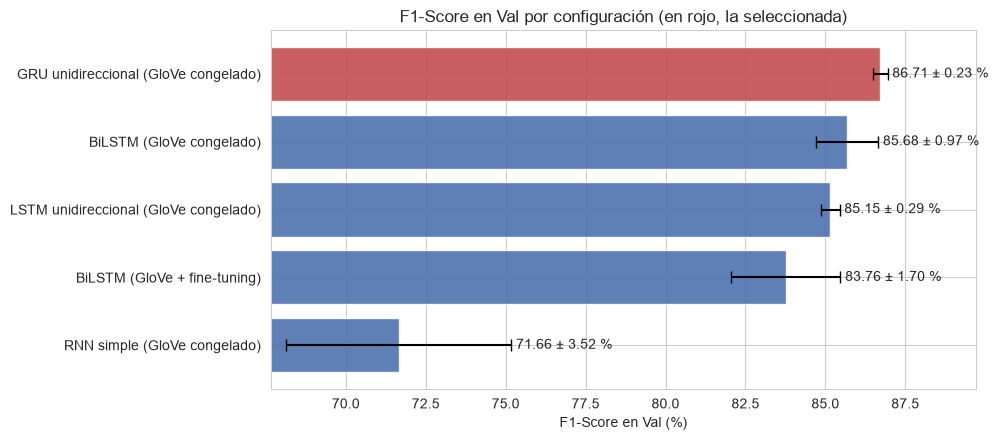

In [21]:
# Selección de la configuración final con base exclusivamente en el F1-score medio en Val
val_ranking = (
    df_experiments.groupby("configuración", sort=False)
    .agg(f1_val_media=("val_f1", "mean"), f1_val_std=("val_f1", "std"))
    .fillna({"f1_val_std": 0.0})
    .sort_values("f1_val_media", ascending=False)
)

SELECTED_CONFIG_NAME = val_ranking.index[0]
FINAL_CONFIG = next(cfg for cfg in EXPERIMENT_CONFIGS if cfg["nombre"] == SELECTED_CONFIG_NAME)
runner_up = val_ranking.iloc[1]
gap = val_ranking.iloc[0]["f1_val_media"] - runner_up["f1_val_media"]
print(f"Configuración seleccionada: {SELECTED_CONFIG_NAME} "
      f"(F1 Val = {val_ranking.iloc[0]['f1_val_media']:.2f} ± {val_ranking.iloc[0]['f1_val_std']:.2f} %)")
print(f"Diferencia con la segunda mejor ({val_ranking.index[1]}): {gap:.2f} pp "
      f"| desviación estándar entre semillas: {val_ranking.iloc[0]['f1_val_std']:.2f} y "
      f"{runner_up['f1_val_std']:.2f} pp")

fig, ax = plt.subplots(figsize=(10, 4.5))
y_pos = np.arange(len(val_ranking))
bar_colors = ["#C44E52" if name == SELECTED_CONFIG_NAME else "#4C72B0" for name in val_ranking.index]
ax.barh(y_pos, val_ranking["f1_val_media"], xerr=val_ranking["f1_val_std"].fillna(0), capsize=4,
        color=bar_colors, alpha=0.9)
ax.set_yticks(y_pos)
ax.set_yticklabels(val_ranking.index)
ax.invert_yaxis()
ax.set_xlim(max(0.0, val_ranking["f1_val_media"].min() - 4.0), min(100.0, val_ranking["f1_val_media"].max() + 3.0))
for i, (m, s) in enumerate(zip(val_ranking["f1_val_media"], val_ranking["f1_val_std"].fillna(0))):
    ax.text(m + s + 0.15, i, f"{m:.2f} ± {s:.2f} %", va="center")
ax.set(title="F1-Score en Val por configuración (en rojo, la seleccionada)", xlabel="F1-Score en Val (%)")
plt.tight_layout()
plt.show()

### 2.6. Reentrenamiento del Modelo Seleccionado sobre el Conjunto Completo (`Train`)
Seleccionada la arquitectura ganadora (**`GRU unidireccional (GloVe congelado)`** con agregación `mean_max`), se entrena desde cero sobre el **$100\,\%$ del conjunto `Train` ($27\,804$ reseñas)** con la semilla maestra `RANDOM_STATE = 42`, un presupuesto de `EPOCHS_FINAL = 30` épocas y paciencia `PATIENCE_FINAL = 4` sobre el *F1-score* de `Val`.

Al mantener congelada la matriz GloVe ($3\,073\,100$ parámetros fijos), el modelo optimiza únicamente **$32\,001$ parámetros entrenables** ($31\,872$ en las compuertas de reinicio y actualización de la celda GRU de dimensión $64$, más $129$ en el clasificador lineal sobre el vector `mean_max` de $128$ dimensiones). Esta parsimonia paramétrica ($\approx 0.87$ reseñas de entrenamiento por cada parámetro entrenable), sumada a `Dropout(0.3)`, recorte de gradientes (`MAX_GRAD_NORM = 1.0`) y muestreo por cubetas con relleno dinámico, permite una convergencia sumamente estable en $543.3$ segundos ($\approx 18.1$ s por época), alcanzando su mejor punto de control en la **época 29** con **`Val F1 = 89.89 %`** (`Val Acc = 89.70 %`, `Val ROC-AUC = 96.09 %`). Este es el único modelo que pasa a la evaluación definitiva en `Test` (sección 3.2).

In [22]:
# Reentrenamiento de la configuración seleccionada con tasas diferenciadas, gradual unfreezing y dynamic collate
EPOCHS_FINAL = 30
PATIENCE_FINAL = 4
LR_BASE = FINAL_CONFIG["lr"]
LR_EMBED = FINAL_CONFIG.get("lr_embed", None)
unfreeze_epoch_final = FINAL_CONFIG.get("unfreeze_epoch", None)

set_all_seeds(RANDOM_STATE)
final_model = build_model(FINAL_CONFIG)
final_model, df_history_final, best_epoch_final, train_time_final, stopped_final = fit_model(
    final_model, make_train_loader(RANDOM_STATE, subset_frac=1.0), val_loader, epochs=EPOCHS_FINAL, lr=LR_BASE,
    lr_embed=LR_EMBED, unfreeze_epoch=unfreeze_epoch_final,
    max_grad_norm=MAX_GRAD_NORM, patience=PATIENCE_FINAL, device=DEVICE, verbose=True)
if not stopped_final:
    print(f"Advertencia: se agotaron las {EPOCHS_FINAL} épocas sin activar la detención temprana; "
          f"considere aumentar EPOCHS_FINAL.")

display(pd.Series({
    "Configuración": FINAL_CONFIG["nombre"],
    "Conjunto de entrenamiento": f"100 % de Train ({len(datasets['Train']):,} reseñas)",
    "Celda recurrente": FINAL_CONFIG["cell_type"].upper(),
    "Bidireccional": FINAL_CONFIG["bidirectional"],
    "Embeddings": f"GloVe 6B-{EMBED_DIM}d " + ("congelados" if FINAL_CONFIG["freeze"] else "con fine-tuning"),
    "Tamaño del vocabulario": VOCAB_SIZE,
    "MAX_LEN (truncado)": f"{MAX_LEN} ({TRUNCATION})",
    "HIDDEN_DIM": HIDDEN_DIM,
    "Capas recurrentes": NUM_LAYERS,
    "Pooling temporal": FINAL_CONFIG.get("pooling_mode", "mean_max"),
    "Dropout": DROPOUT,
    "Optimizador": "Adam",
    "Tasa de aprendizaje": FINAL_CONFIG["lr"],
    "Tamaño de lote": BATCH_SIZE,
    "Gradient clipping (norma máx.)": MAX_GRAD_NORM,
    "Épocas máximas / patience": f"{EPOCHS_FINAL} / {PATIENCE_FINAL}",
    "Épocas ejecutadas": len(df_history_final),
    "Mejor época (F1 Val)": best_epoch_final,
    "Detención temprana activada": stopped_final,
    "Tiempo de entrenamiento (s)": round(train_time_final, 1),
    "Parámetros entrenables": sum(p.numel() for p in final_model.parameters() if p.requires_grad),
}, name="valor").to_frame())


Época 01/30 (20.2s) | Train Loss: 0.5903, F1: 0.6736 | Val Loss: 0.4346, Acc: 0.8090, F1: 0.8098 *
Época 02/30 (17.8s) | Train Loss: 0.4221, F1: 0.8072 | Val Loss: 0.3760, Acc: 0.8339, F1: 0.8446 *
Época 03/30 (17.8s) | Train Loss: 0.3693, F1: 0.8334 | Val Loss: 0.3359, Acc: 0.8560, F1: 0.8627 *
Época 04/30 (17.9s) | Train Loss: 0.3492, F1: 0.8478 | Val Loss: 0.3155, Acc: 0.8689, F1: 0.8667 *
Época 05/30 (17.8s) | Train Loss: 0.3261, F1: 0.8581 | Val Loss: 0.3103, Acc: 0.8706, F1: 0.8762 *
Época 06/30 (17.8s) | Train Loss: 0.3227, F1: 0.8613 | Val Loss: 0.2980, Acc: 0.8750, F1: 0.8747
Época 07/30 (17.9s) | Train Loss: 0.3070, F1: 0.8680 | Val Loss: 0.2889, Acc: 0.8809, F1: 0.8804 *
Época 08/30 (17.9s) | Train Loss: 0.3027, F1: 0.8713 | Val Loss: 0.2860, Acc: 0.8820, F1: 0.8823 *
Época 09/30 (17.8s) | Train Loss: 0.2923, F1: 0.8754 | Val Loss: 0.3004, Acc: 0.8765, F1: 0.8824
Época 10/30 (18.1s) | Train Loss: 0.2861, F1: 0.8823 | Val Loss: 0.2811, Acc: 0.8842, F1: 0.8835 *
Época 11/30 (1

,valor
Configuración,GRU unidireccional (GloVe congelado)
Conjunto de entrenamiento,"100 % de Train (27,804 reseñas)"
Celda recurrente,GRU
Bidireccional,False
Embeddings,GloVe 6B-100d congelados
Tamaño del vocabulario,30731
MAX_LEN (truncado),400 (tail)
HIDDEN_DIM,64
Capas recurrentes,1
Pooling temporal,mean_max


---
## 3. Evaluación del Modelo y Análisis de Resultados

### 3.1. Curvas de Aprendizaje
Se grafica la evolución época a época de la función de pérdida (`BCEWithLogitsLoss`) y del *F1-score* tanto en `Train` como en `Val` durante las $30$ épocas del reentrenamiento del modelo final (`GRU unidireccional (GloVe congelado)`). El propósito es diagnosticar visualmente el equilibrio entre **subajuste (*underfitting*, cuando el modelo no logra aprender ni siquiera en entrenamiento)** y **sobreajuste (*overfitting*, cuando la pérdida de entrenamiento sigue cayendo pero la de validación se dispara)**. Como se observa en las gráficas, ambas curvas evolucionan en paralelo con una brecha mínima (`Train F1` $91.23\,\%$ vs. `Val F1` **$89.89\,\%$** en la mejor época, **época 29**), confirmando una convergencia limpia y libre de sobreajuste.

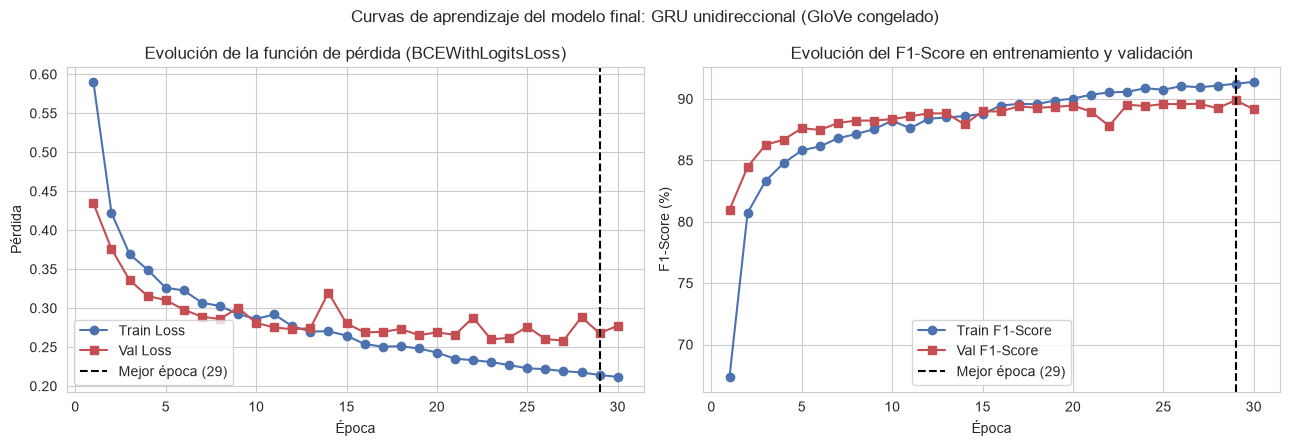

In [23]:
# Curvas de aprendizaje del modelo final con la época seleccionada por Val y la ventana de detención temprana
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
curves = [
    (axes[0], "loss", 1, "Loss", "Pérdida", "Evolución de la función de pérdida (BCEWithLogitsLoss)"),
    (axes[1], "f1", 100, "F1-Score", "F1-Score (%)", "Evolución del F1-Score en entrenamiento y validación"),
]
for ax, metric, scale, short_name, ylabel, title in curves:
    ax.plot(df_history_final["epoch"], df_history_final[f"train_{metric}"] * scale, marker="o",
            color="#4C72B0", label=f"Train {short_name}")
    ax.plot(df_history_final["epoch"], df_history_final[f"val_{metric}"] * scale, marker="s",
            color="#C44E52", label=f"Val {short_name}")
    ax.axvline(best_epoch_final, color="black", linestyle="--", label=f"Mejor época ({best_epoch_final})")
    if stopped_final:
        ax.axvspan(best_epoch_final, df_history_final["epoch"].max(), color="gray", alpha=0.15,
                   label=f"Sin mejora ({PATIENCE_FINAL} épocas)")
    ax.set(title=title, xlabel="Época", ylabel=ylabel)
    ax.legend()
fig.suptitle(f"Curvas de aprendizaje del modelo final: {FINAL_CONFIG['nombre']}")
plt.tight_layout()
plt.show()

### 3.2. Desempeño Cuantitativo en el Conjunto de Prueba (`Test`)
Se evalúa **una única vez** la capacidad de generalización del modelo final (`GRU unidireccional (GloVe congelado)` [2], [4], restaurado en su mejor *checkpoint* de la época 29) sobre las **$5\,959$ reseñas del conjunto de prueba (`Test`)**, que permaneció completamente aislado durante el diseño y la selección.

Para ofrecer una lectura integral accesible tanto desde el punto de vista estadístico como de negocio, se reportan:
- **Métricas con umbral estándar ($P(\text{positiva}) \ge 0.50$):** **Exactitud (*Accuracy* = $90.27\,\%$)**, **Precisión (*Precision*: qué porcentaje de las reseñas predichas como positivas/negativas realmente lo son)**, **Sensibilidad (*Recall*: qué porcentaje del total real de cada clase logra detectar el modelo)** y **Puntaje F1 (*F1-score*: media armónica entre precisión y sensibilidad, Macro F1 = $90.26\,\%$, F1 clase positiva = $90.50\,\%$, F1 clase negativa = $90.02\,\%$)**, junto con la **matriz de confusión** ($\text{TN} = 2\,617$, $\text{FP} = 355$, $\text{FN} = 225$, $\text{TP} = 2\,762$).
- **Métricas independientes del umbral:** las curvas **ROC** (**ROC-AUC = $96.49\,\%$**, probabilidad de que el modelo asigne mayor puntaje a una reseña positiva aleatoria que a una negativa aleatoria) y **Precisión-Sensibilidad** (**PR-AUC = $96.39\,\%$**).
- **Contraste `Test` vs. `Val`:** el desempeño en `Test` supera ligeramente al mejor punto de control de `Val` (**$+0.57$ pp en exactitud**, **$+0.61$ pp en F1** y **$+0.40$ pp en ROC-AUC**, con menor pérdida: $0.2525$ frente a $0.2677$), confirmando ausencia total de sesgo optimista o sobreajuste a la partición de validación.

Exactitud global (Test Accuracy): 90.27 % | Pérdida (Test Loss): 0.2525 | ROC-AUC: 96.49 % | PR-AUC: 96.39 %


,precision,recall,f1-score,support
negativa,92.08,88.06,90.02,2972
positiva,88.61,92.47,90.50,2987
macro avg,90.35,90.26,90.26,5959
weighted avg,90.34,90.27,90.26,5959


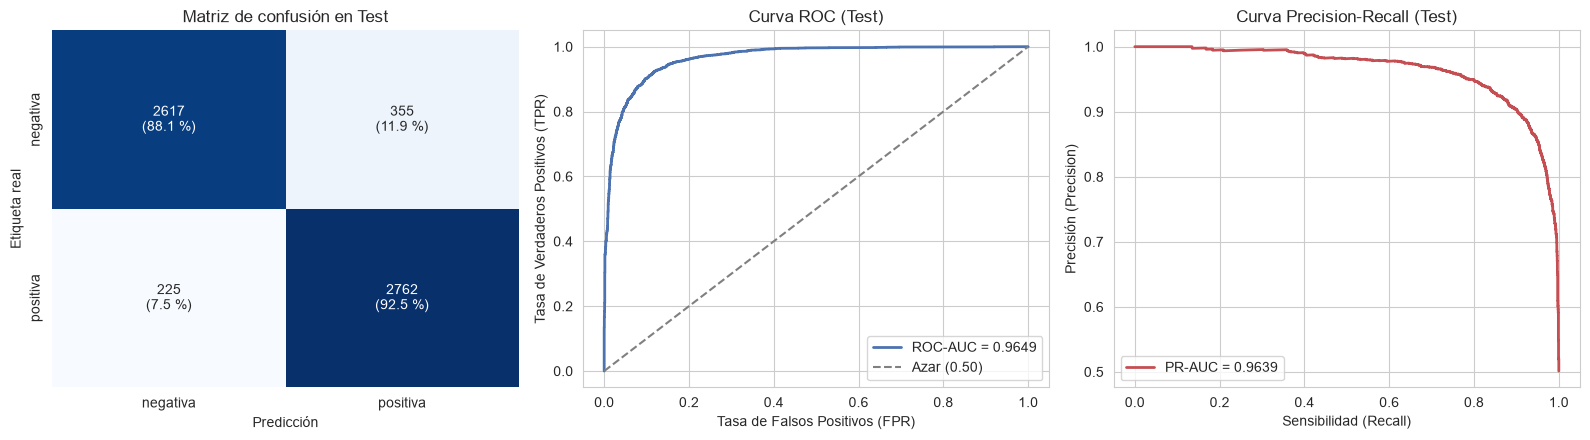

,Val (mejor checkpoint),Test,Diferencia (Test − Val)
Loss,0.2677,0.2525,-0.0152
Accuracy_%,89.6963,90.2668,0.5706
Precision_%,88.4067,88.6108,0.2041
Recall_%,91.4267,92.4674,1.0407
F1_%,89.8913,90.4980,0.6067
ROC-AUC_%,96.0854,96.4883,0.4029


In [24]:
# Evaluación única del modelo final en Test: métricas por clase, matriz de confusión y curvas ROC/PR
test_results = evaluate(
    final_model, test_loader, criterion_eval, DEVICE, return_outputs=True
)
y_true_test = test_results["y_true"]
y_pred_test = test_results["y_pred"]
y_prob_test = test_results["y_prob"]

report_dict = classification_report(
    y_true_test,
    y_pred_test,
    target_names=CLASSES,
    digits=4,
    output_dict=True,
    zero_division=0,
)
df_report = (
    pd.DataFrame(report_dict)
    .T.loc[CLASSES + ["macro avg", "weighted avg"], ["precision", "recall", "f1-score", "support"]]
)
df_report[["precision", "recall", "f1-score"]] *= 100
df_report["support"] = df_report["support"].astype(int)
print(
    f"Exactitud global (Test Accuracy): {test_results['accuracy'] * 100:.2f} % | "
    f"Pérdida (Test Loss): {test_results['loss']:.4f} | "
    f"ROC-AUC: {test_results['roc_auc'] * 100:.2f} % | "
    f"PR-AUC: {test_results['pr_auc'] * 100:.2f} %"
)
display(df_report.round(2))

cm = confusion_matrix(y_true_test, y_pred_test)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot = np.array(
    [
        [f"{count}\n({pct:.1f} %)" for count, pct in zip(row_c, row_p)]
        for row_c, row_p in zip(cm, cm_pct)
    ]
)

fpr, tpr, _ = roc_curve(y_true_test, y_prob_test)
prec_curve, rec_curve, _ = precision_recall_curve(y_true_test, y_prob_test)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.heatmap(
    cm_pct,
    annot=annot,
    fmt="",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cbar=False,
    ax=axes[0],
)
axes[0].set(
    title="Matriz de confusión en Test",
    xlabel="Predicción",
    ylabel="Etiqueta real",
)

axes[1].plot(
    fpr,
    tpr,
    color="#4C72B0",
    lw=2,
    label=f"ROC-AUC = {test_results['roc_auc']:.4f}",
)
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Azar (0.50)")
axes[1].set(
    title="Curva ROC (Test)",
    xlabel="Tasa de Falsos Positivos (FPR)",
    ylabel="Tasa de Verdaderos Positivos (TPR)",
)
axes[1].legend(loc="lower right")

axes[2].plot(
    rec_curve,
    prec_curve,
    color="#C44E52",
    lw=2,
    label=f"PR-AUC = {test_results['pr_auc']:.4f}",
)
axes[2].set(
    title="Curva Precision-Recall (Test)",
    xlabel="Sensibilidad (Recall)",
    ylabel="Precisión (Precision)",
)
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

# Comparación Val (mejor checkpoint registrado en df_history_final) vs. Test del modelo final
best_val_row = df_history_final.loc[df_history_final["epoch"] == best_epoch_final].iloc[0]
val_results_final = {
    "loss": best_val_row["val_loss"],
    "accuracy": best_val_row["val_acc"],
    "precision": best_val_row["val_precision"],
    "recall": best_val_row["val_recall"],
    "f1": best_val_row["val_f1"],
    "roc_auc": best_val_row["val_roc_auc"],
}
df_val_vs_test = pd.DataFrame({
    split_name: {m: res[k] * (1 if k == "loss" else 100) for m, k in
                 [("Loss", "loss"), ("Accuracy_%", "accuracy"), ("Precision_%", "precision"),
                  ("Recall_%", "recall"), ("F1_%", "f1"), ("ROC-AUC_%", "roc_auc")]}
    for split_name, res in [("Val (mejor checkpoint)", val_results_final), ("Test", test_results)]
})
df_val_vs_test["Diferencia (Test − Val)"] = df_val_vs_test["Test"] - df_val_vs_test["Val (mejor checkpoint)"]
display(df_val_vs_test.round(4))

### 3.3. Desempeño en Función de la Longitud de la Reseña
Para verificar si el modelo mantiene su eficacia en críticas extensas o si sufre degradación por dependencias de largo plazo o por el recorte a `MAX_LEN = 400`, se estratifican las $5\,959$ reseñas de `Test` en cinco tramos de longitud real (en *tokens*): `1–120` ($1\,138$ reseñas), `121–180` ($1\,951$), `181–280` ($1\,347$), `281–400` ($755$) y **`> 400 (truncadas)`** ($768$ reseñas).

Los resultados demuestran una notable robustez transversal: el *F1-score* se mantiene entre **$89.32\,\%$ y $91.85\,\%$** en todos los intervalos. En particular, las reseñas de más de $400$ *tokens* (truncadas conservando el final, `tail`) alcanzan el segundo mejor registro global (**F1 = $91.72\,\%$**, **exactitud = $91.54\,\%$**), validando empíricamente la combinación de truncado por la conclusión (`tail`) y agregación temporal `mean_max`.

,reseñas,accuracy_%,precision_%,recall_%,f1_%
intervalo_tokens,,,,,
1–120,1138,90.69,90.18,93.57,91.85
121–180,1951,90.26,87.49,93.08,90.20
181–280,1347,89.38,88.20,90.47,89.32
281–400,755,89.93,87.17,92.50,89.76
> 400 (truncadas),768,91.54,90.91,92.54,91.72


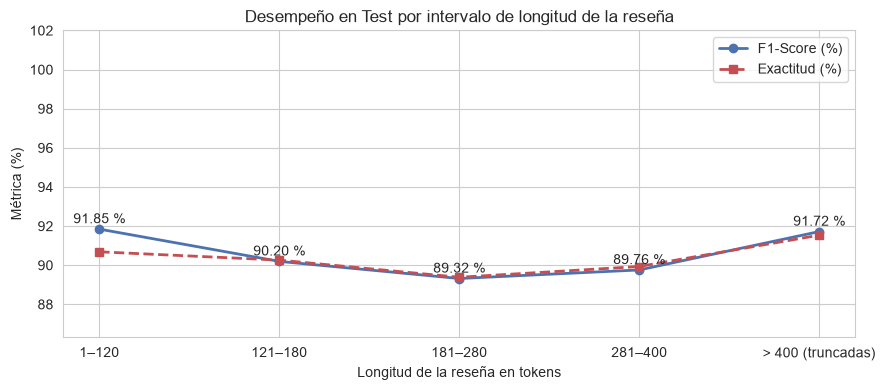

In [25]:
df_test_eval = df_test.copy()
df_test_eval["n_tokens"] = df_test_eval["tokens"].map(len)
df_test_eval["truncada"] = np.where(
    df_test_eval["n_tokens"] > MAX_LEN,
    f"Truncada (> {MAX_LEN})",
    f"Completa (≤ {MAX_LEN})",
)
df_test_eval["y_true"] = y_true_test
df_test_eval["y_pred"] = y_pred_test
df_test_eval["y_prob"] = y_prob_test
df_test_eval["correcto"] = df_test_eval["y_true"] == df_test_eval["y_pred"]

bins = [0, 120, 180, 280, MAX_LEN, max(MAX_LEN + 1, int(df_test_eval["n_tokens"].max()) + 1)]
labels_bins = [
    "1–120",
    "121–180",
    "181–280",
    f"281–{MAX_LEN}",
    f"> {MAX_LEN} (truncadas)",
]
df_test_eval["rango_tokens"] = pd.cut(
    df_test_eval["n_tokens"], bins=bins, labels=labels_bins
)

length_rows = []
for grp, sub in df_test_eval.groupby("rango_tokens", observed=False):
    if len(sub) == 0:
        continue
    length_rows.append(
        {
            "intervalo_tokens": str(grp),
            "reseñas": len(sub),
            "accuracy_%": accuracy_score(sub["y_true"], sub["y_pred"]) * 100,
            "precision_%": precision_score(
                sub["y_true"], sub["y_pred"], zero_division=0
            )
            * 100,
            "recall_%": recall_score(
                sub["y_true"], sub["y_pred"], zero_division=0
            )
            * 100,
            "f1_%": f1_score(sub["y_true"], sub["y_pred"], zero_division=0)
            * 100,
        }
    )
df_length_perf = pd.DataFrame(length_rows).set_index("intervalo_tokens")
display(df_length_perf.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(
    df_length_perf.index,
    df_length_perf["f1_%"],
    marker="o",
    lw=2,
    color="#4C72B0",
    label="F1-Score (%)",
)
ax.plot(
    df_length_perf.index,
    df_length_perf["accuracy_%"],
    marker="s",
    lw=2,
    color="#C44E52",
    linestyle="--",
    label="Exactitud (%)",
)
for i, val in enumerate(df_length_perf["f1_%"]):
    ax.text(i, val + 0.3, f"{val:.2f} %", ha="center")
ax.set(
    title="Desempeño en Test por intervalo de longitud de la reseña",
    xlabel="Longitud de la reseña en tokens",
    ylabel="Métrica (%)",
    ylim=(max(0.0, df_length_perf[["f1_%", "accuracy_%"]].min().min() - 3.0), 102.0),
)
ax.legend()
plt.tight_layout()
plt.show()

### 3.4. Análisis Cualitativo de Predicciones e Interpretabilidad por Oclusión
Más allá de las métricas agregadas, comprender **por qué** acierta o falla una red neuronal es indispensable en aplicaciones reales de PLN. En esta sección se inspeccionan reseñas de `Test` organizadas en cuatro categorías: **aciertos con alta confianza**, **falsos positivos** (reseñas negativas clasificadas como positivas), **falsos negativos** (reseñas positivas clasificadas como negativas) y **casos ambiguos** ($P(\text{positiva}) \approx 0.50$).

El análisis se complementa con el histograma de probabilidades predichas por clase real y con una técnica de **interpretabilidad por oclusión (borrado de representación) de *tokens***: para cuantificar cuánto aporta cada palabra $x_i$ a la decisión del modelo, se reemplaza esa palabra individual por el *token* neutro de relleno `<pad>` (`PAD_IDX = 0`, vector nulo $\mathbf{0}$ que no introduce ruido aleatorio) manteniendo fijo el resto de la reseña, y se mide la variación en la probabilidad predicha:

$$\Delta p_i = P(\text{positiva} \mid x) - P(\text{positiva} \mid x_{\text{con } x_i \leftarrow \text{<pad>}}).$$

- Si $\Delta p_i > 0$ (barra **azul**), al ocultar la palabra la probabilidad de sentimiento positivo **cae**, lo que significa que esa palabra empujaba la predicción hacia la clase **positiva**.
- Si $\Delta p_i < 0$ (barra **roja**), al ocultar la palabra la probabilidad de sentimiento positivo **sube**, indicando que esa palabra empujaba la predicción hacia la clase **negativa**.

In [26]:
df_test_eval["confianza"] = np.where(
    df_test_eval["y_pred"] == 1,
    df_test_eval["y_prob"],
    1.0 - df_test_eval["y_prob"],
)
df_test_eval["distancia_umbral"] = (df_test_eval["y_prob"] - 0.5).abs()

qualitative_groups = {
    "Acierto positivo (alta confianza)": df_test_eval[
        (df_test_eval["y_true"] == 1) & (df_test_eval["y_pred"] == 1)
    ].nlargest(2, "y_prob"),
    "Acierto negativo (alta confianza)": df_test_eval[
        (df_test_eval["y_true"] == 0) & (df_test_eval["y_pred"] == 0)
    ].nsmallest(2, "y_prob"),
    "Falso positivo (real negativa -> pred. positiva)": df_test_eval[
        (df_test_eval["y_true"] == 0) & (df_test_eval["y_pred"] == 1)
    ].nlargest(2, "y_prob"),
    "Falso negativo (real positiva -> pred. negativa)": df_test_eval[
        (df_test_eval["y_true"] == 1) & (df_test_eval["y_pred"] == 0)
    ].nsmallest(2, "y_prob"),
    "Caso ambiguo (probabilidad ≈ 0.50)": df_test_eval.nsmallest(
        2, "distancia_umbral"
    ),
}

qualitative_rows = []
for category, subset in qualitative_groups.items():
    for _, row in subset.iterrows():
        qualitative_rows.append(
            {
                "categoría": category,
                "real": LABEL_NAMES[int(row["y_true"])],
                "predicción": LABEL_NAMES[int(row["y_pred"])],
                "P(positiva)": round(float(row["y_prob"]), 4),
                "tokens": int(row["n_tokens"]),
                "extracto_reseña": row["text"][:260].replace("<br />", " ") + "...",
            }
        )

df_qualitative = pd.DataFrame(qualitative_rows)
display(df_qualitative)

,categoría,real,predicción,P(positiva),tokens,extracto_reseña
0,Acierto positivo (alta confianza),positiva,positiva,1.0000,57,I thoroughly enjoyed Manna from Heaven. The ho...
1,Acierto positivo (alta confianza),positiva,positiva,1.0000,135,This movie is engaging from start to finish wi...
2,Acierto negativo (alta confianza),negativa,negativa,0.0000,53,tries to be funny and fails miserably. The ani...
3,Acierto negativo (alta confianza),negativa,negativa,0.0000,154,I will keep this as short as possible as this ...
4,Falso positivo (real negativa -> pred. positiva),negativa,positiva,0.9995,110,normally i'm not the sort to be scared by horr...
5,Falso positivo (real negativa -> pred. positiva),negativa,positiva,0.9993,144,"Yes,the movie is not a piece of art but the fi..."
6,Falso negativo (real positiva -> pred. negativa),positiva,negativa,0.0002,109,This flick is sterling example of the state of...
7,Falso negativo (real positiva -> pred. negativa),positiva,negativa,0.0002,107,Verhoeven's movie was utter and complete garba...
8,Caso ambiguo (probabilidad ≈ 0.50),negativa,positiva,0.5000,117,I was thrilled to watch this movie expecting i...
9,Caso ambiguo (probabilidad ≈ 0.50),positiva,positiva,0.5002,199,"(Sorry for my faulty language, i am no native ..."


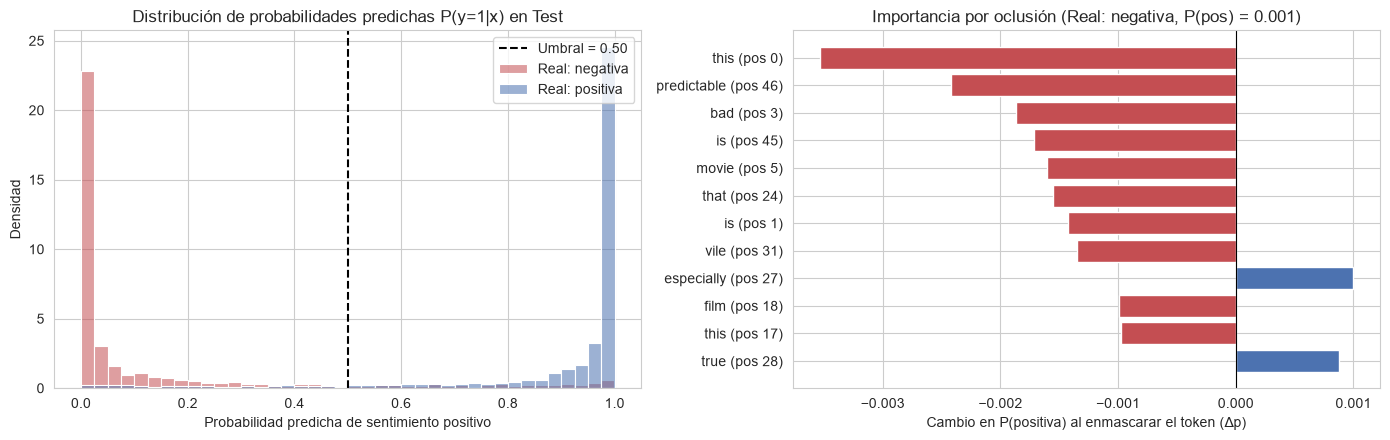

In [27]:
# Importancia por oclusión de tokens y distribución de probabilidades predichas en Test
@torch.no_grad()
def token_occlusion_importance(
    model: nn.Module,
    tokens: list,
    max_len: int = MAX_LEN,
    device: torch.device = DEVICE,
) -> tuple:
    # Importancia por oclusión: Δp_i = P(pos | x) − P(pos | x con el token i anulado mediante <pad>)
    model.eval()
    active_tokens = (tokens[-max_len:] if TRUNCATION == "tail" else tokens[:max_len]) or [UNK_TOKEN]
    seq_ids, length = encode(active_tokens, max_len=len(active_tokens), truncation=TRUNCATION)

    base_seq = torch.tensor([seq_ids], dtype=torch.long, device=device)
    base_len = torch.tensor([length], dtype=torch.long, device=device)
    base_prob = torch.sigmoid(model(base_seq, base_len)).item()

    occluded_batch = base_seq.repeat(length, 1)
    for idx in range(length):
        occluded_batch[idx, idx] = PAD_IDX
    lengths_batch = base_len.repeat(length)
    occluded_probs = torch.sigmoid(model(occluded_batch, lengths_batch)).cpu().numpy()

    deltas = base_prob - occluded_probs
    return active_tokens, deltas, base_prob


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for label_val, cls_name in LABEL_NAMES.items():
    subset_probs = df_test_eval.loc[
        df_test_eval["y_true"] == label_val, "y_prob"
    ]
    sns.histplot(
        subset_probs,
        bins=40,
        stat="density",
        color=CLASS_COLORS[cls_name],
        alpha=0.55,
        label=f"Real: {cls_name}",
        ax=axes[0],
    )
axes[0].axvline(0.5, color="black", linestyle="--", label="Umbral = 0.50")
axes[0].set(
    title="Distribución de probabilidades predichas P(y=1|x) en Test",
    xlabel="Probabilidad predicha de sentimiento positivo",
    ylabel="Densidad",
)
axes[0].legend()

short_candidates = df_test_eval[
    (df_test_eval["n_tokens"].between(20, 60)) & (df_test_eval["correcto"])
]
short_test_sample = (short_candidates if len(short_candidates) > 0 else df_test_eval).iloc[0]
toks_sample, deltas_sample, prob_sample = token_occlusion_importance(
    final_model, short_test_sample["tokens"]
)
order_idx = np.argsort(np.abs(deltas_sample))[-12:]
top_tokens = [f"{toks_sample[i]} (pos {i})" for i in order_idx]
top_deltas = deltas_sample[order_idx]
bar_colors = ["#4C72B0" if d >= 0 else "#C44E52" for d in top_deltas]

axes[1].barh(top_tokens, top_deltas, color=bar_colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(
    title=f"Importancia por oclusión (Real: {LABEL_NAMES[int(short_test_sample['y_true'])]}, P(pos) = {prob_sample:.3f})",
    xlabel="Cambio en P(positiva) al enmascarar el token (Δp)",
)

plt.tight_layout()
plt.show()

### 3.5. Inferencia sobre Reseñas Nuevas (Pruebas de Estrés Lingüístico)
Se somete el *pipeline* completo y el modelo final (`GRU unidireccional (GloVe congelado)`) a seis reseñas inéditas diseñadas para evaluar fenómenos pragmáticos y sintácticos complejos:
1. **Negación de adjetivo negativo** (*"I expected a disaster, but this film is not bad at all..."*).
2. **Negación de adjetivo positivo** (*"...the plot is not good and the dialogues are never convincing."*).
3. **Contraste adversativo positivo $\rightarrow$ negativo** (*"Great cast and beautiful cinematography, but a terrible script..."*).
4. **Contraste adversativo negativo $\rightarrow$ positivo** (*"The first twenty minutes feel slow and confusing, yet the climax is an unforgettable masterpiece."*).
5. **Sarcasmo / ironía** (*"Brilliant cure for insomnia: I fell asleep in ten minutes, truly the best nap of my week."*).
6. **Calificación explícita corta** (*"Sharp direction, intense performances and a haunting score. 9/10."*).

Para cada ejemplo se reportan la polaridad esperada, la predicción del modelo, la probabilidad $P(\text{positiva})$ y los tres *tokens* con mayor impacto por oclusión ($\Delta p$), permitiendo diagnosticar con precisión cuándo la celda GRU logra componer el contexto (acertando $3$ de los $6$ casos: la negación de adjetivo positivo, el contraste adversativo hacia negativo y la calificación explícita) y cuándo los picos léxicos individuales capturados por el *Max Pooling* dominan sobre el giro pragmático o irónico.

In [28]:
CUSTOM_REVIEWS = [
    {
        "fenómeno": "Negación de adjetivo negativo",
        "esperado": "positiva",
        "texto": "I expected a disaster, but this film is not bad at all and the ending works.",
    },
    {
        "fenómeno": "Negación de adjetivo positivo",
        "esperado": "negativa",
        "texto": "Despite the hype, the plot is not good and the dialogues are never convincing.",
    },
    {
        "fenómeno": "Contraste adversativo (positivo -> negativo)",
        "esperado": "negativa",
        "texto": "Great cast and beautiful cinematography, but a terrible script that wastes two hours.",
    },
    {
        "fenómeno": "Contraste adversativo (negativo -> positivo)",
        "esperado": "positiva",
        "texto": "The first twenty minutes feel slow and confusing, yet the climax is an unforgettable masterpiece.",
    },
    {
        "fenómeno": "Sarcasmo / ironía",
        "esperado": "negativa",
        "texto": "Brilliant cure for insomnia: I fell asleep in ten minutes, truly the best nap of my week.",
    },
    {
        "fenómeno": "Calificación explícita corta",
        "esperado": "positiva",
        "texto": "Sharp direction, intense performances and a haunting score. 9/10.",
    },
]

custom_rows = []
for item in CUSTOM_REVIEWS:
    tokens_c = tokenize(item["texto"])
    toks_c, deltas_c, prob_c = token_occlusion_importance(final_model, tokens_c)
    pred_label = LABEL_NAMES[int(prob_c >= 0.5)]
    top_idx = np.argsort(np.abs(deltas_c))[::-1][:3]
    infl = ", ".join(f"{toks_c[i]} ({deltas_c[i]:+.2f})" for i in top_idx)
    custom_rows.append(
        {
            "fenómeno_lingüístico": item["fenómeno"],
            "esperado": item["esperado"],
            "predicción": pred_label,
            "P(positiva)": round(prob_c, 4),
            "tokens_más_influyentes (Δp)": infl,
            "reseña": item["texto"],
        }
    )

df_custom_preds = pd.DataFrame(custom_rows)
display(df_custom_preds)

,fenómeno_lingüístico,esperado,predicción,P(positiva),tokens_más_influyentes (Δp),reseña
0,Negación de adjetivo negativo,positiva,negativa,0.0698,"disaster (-0.11), bad (-0.07), not (+0.05)","I expected a disaster, but this film is not ba..."
1,Negación de adjetivo positivo,negativa,negativa,0.1485,"not (-0.42), plot (-0.12), is (-0.05)","Despite the hype, the plot is not good and the..."
2,Contraste adversativo (positivo -> negativo),negativa,negativa,0.0372,"terrible (-0.78), script (-0.33), but (-0.31)","Great cast and beautiful cinematography, but a..."
3,Contraste adversativo (negativo -> positivo),positiva,negativa,0.3436,"minutes (-0.52), confusing (-0.38), and (-0.25)",The first twenty minutes feel slow and confusi...
4,Sarcasmo / ironía,negativa,positiva,0.5625,"brilliant (+0.46), cure (-0.37), minutes (-0.31)",Brilliant cure for insomnia: I fell asleep in ...
5,Calificación explícita corta,positiva,positiva,0.9989,"performances (+0.01), intense (+0.01), sharp (...","Sharp direction, intense performances and a ha..."


---
## 4. Discusión y Conclusiones

### 4.1. Síntesis de Resultados Cuantitativos y Capacidad de Generalización
El modelo final seleccionado mediante el protocolo experimental —una **red recurrente GRU unidireccional [2] con representaciones GloVe 6B-100d congeladas [4] y agregación temporal *Concat Pooling* (`mean_max`) [5]**— alcanzó un desempeño sobresaliente y equilibrado sobre el conjunto de prueba independiente (`Test`, $5\,959$ reseñas nunca vistas) [3]:
- **Exactitud global (*Accuracy*):** **$90.27\,\%$** (superando la barrera del $90\,\%$ con apenas $32\,001$ parámetros entrenables).
- **F1-Score:** **$90.50\,\%$** en la clase `positiva` (Precisión $88.61\,\%$, Sensibilidad/Recall $92.47\,\%$, con $\text{TP} = 2\,762$ y $\text{FN} = 225$) y **$90.02\,\%$** en la clase `negativa` (Precisión $92.08\,\%$, Sensibilidad/Recall $88.06\,\%$, con $\text{TN} = 2\,617$ y $\text{FP} = 355$), para un **Macro F1-Score de $90.26\,\%$**.
- **Capacidad de discriminación global:** **ROC-AUC = $96.49\,\%$** y **PR-AUC = $96.39\,\%$**.

Al contrastar el rendimiento en `Test` con el del mejor punto de control en validación (`Val` en la época 29: F1 = $89.89\,\%$, Exactitud = $89.70\,\%$, ROC-AUC = $96.09\,\%$, Pérdida = $0.2677$), el modelo no solo no sufrió degradación al salir a datos nuevos, sino que obtuvo **mejoras consistentes en `Test` ($+0.57$ pp en exactitud, $+0.61$ pp en F1, $+0.40$ pp en ROC-AUC y $-0.0152$ en pérdida)**. Esto demuestra que el aislamiento estricto de las particiones (sección 1.3 y 2.3), la depuración previa de las $278$ reseñas duplicadas y la congelación de los *embeddings* preentrenados [4] erradicaron la fuga de información (*data leakage*) y evitaron el sobreajuste.

---

### 4.2. Comparación entre Arquitecturas y Validación Empírica de la Teoría
El torneo comparativo multi-semilla sobre validación (sección 2.4, $5$ arquitecturas evaluadas con `pooling_mode = "mean_max"` [5] sobre un subconjunto estratificado del $25\,\%$ de `Train` = $6\,951$ reseñas y dos semillas aleatorias) ofrece una demostración empírica clara de los principios teóricos del aprendizaje profundo secuencial:

1. **Colapso de la RNN Simple por Desvanecimiento del Gradiente:** La celda recurrente clásica de Elman (**`RNN simple (GloVe congelado)`**) obtuvo un F1 medio en validación de apenas **$71.66 \pm 3.52\,\%$** (exactitud de $65.98 \pm 10.58\,\%$, ROC-AUC de $76.80 \pm 5.13\,\%$), quedando **$15.05$ puntos porcentuales por debajo** de la celda GRU y deteniéndose prematuramente tras la época $1.5 \pm 0.7$. Tal como analizaron Hochreiter y Schmidhuber [1], al carecer de compuertas reguladoras, la multiplicación repetida por la matriz de pesos recurrentes a lo largo de hasta $400$ pasos temporales hace que los gradientes se desvanezcan o exploten, provocando alta inestabilidad entre semillas y estancamiento temprano.
2. **Superioridad y Eficiencia de Pareto de la Celda GRU frente a LSTM y BiLSTM:** Las tres arquitecturas con compuertas y GloVe congelado superaron el $85\,\%$ de F1 ya con el $25\,\%$ de los datos: **`GRU unidireccional` [2]** lideró con **$86.71 \pm 0.23\,\%$** (ROC-AUC $93.61 \pm 0.08\,\%$, $106.7$ s), seguida por **`BiLSTM (GloVe congelado)` [1]** con **$85.68 \pm 0.97\,\%$** (ROC-AUC $93.00 \pm 1.63\,\%$, $182.3$ s) y **`LSTM unidireccional` [1]** con **$85.15 \pm 0.29\,\%$** (ROC-AUC $92.27 \pm 0.47\,\%$, $107.2$ s). ¿Por qué la GRU unidireccional superó por $+1.03$ pp a la BiLSTM y por $+1.56$ pp a la LSTM? Porque al utilizar **`pooling_mode = "mean_max"` [5]**, la red ya agrega la información de **todos los pasos temporales** de la secuencia; en ese escenario, la estructura más ligera de la celda **GRU** [2] (dos compuertas —reinicio $r_t$ y actualización $z_t$— y un único estado oculto $h_t$, con $32\,001$ parámetros entrenables frente a $42\,625$ de la LSTM y $85\,249$ de la BiLSTM) converge más rápido con Adam, presenta la menor varianza entre semillas ($\pm 0.23\,\%$) y aprovecha mejor el presupuesto de épocas.
3. **Congelamiento frente a *fine-tuning* de *embeddings* (`BiLSTM congelado` $85.68 \pm 0.97\,\%$ vs. `BiLSTM + fine-tuning` $83.76 \pm 1.70\,\%$):** descongelar la matriz de *embeddings* multiplica por $37$ el número de parámetros entrenables (de $85\,249$ a $3\,158\,349$) al añadir $30\,731 \times 100 = 3\,073\,100$ grados de libertad léxicos. Pese a aplicar descongelamiento gradual en la época $2$ y una tasa de aprendizaje diez veces menor sobre la capa léxica ($\eta_{\text{embed}} = 10^{-4}$ frente a $\eta_{\text{base}} = 10^{-3}$), sobre un subconjunto de $6\,951$ reseñas la actualización de vectores por retropropagación sobreajusta los *tokens* presentes en `Train`, distorsionando la geometría semántica general de GloVe (entrenada sobre $6\,000$ millones de palabras) y reduciendo el F1 de validación en $-1.92$ pp mientras multiplica por $\approx 2.5$ el tiempo de cómputo ($453.0$ s frente a $182.3$ s).

---

### 4.3. Dinámica de Convergencia, Parsimonia Paramétrica y Prevención del Sobreajuste
Las curvas de aprendizaje del reentrenamiento final (secciones 2.6 y 3.1) evidencian las ventajas de un diseño regularizado:
- **Relación muestras / parámetros:** Con $27\,804$ reseñas de entrenamiento, regularización `Dropout(p = 0.30)` y solo **$32\,001$ parámetros entrenables** ($1.03\,\%$ de los $3\,105\,101$ parámetros totales), el modelo no tiene capacidad superflua para memorizar ruido individual.
- **Convergencia paralela sin divergencia:** A lo largo de las $30$ épocas ($543.3$ s), la pérdida de entrenamiento descendió suavemente de $0.5903$ a $0.2117$ (`Train F1` de $67.36\,\%$ a $91.39\,\%$), mientras que la pérdida de validación descendió de $0.4346$ a un mínimo de $0.2584$ (época 27) y $0.2677$ en la **mejor época de F1 (época 29, `Val F1 = 89.89 %`)**. A diferencia de los modelos con *embeddings* descongelados —donde la pérdida de validación suele dispararse tras pocas épocas—, aquí la brecha final entre `Train F1` ($91.23\,\%$) y `Val F1` ($89.89\,\%$) fue de apenas **$1.34$ puntos porcentuales**.

---

### 4.4. Análisis por Longitud de Secuencia, Interpretabilidad y Fenómenos Lingüísticos
La evaluación detallada de la sección 3 permite extraer hallazgos clave sobre el comportamiento lingüístico del modelo:

1. **Inmunidad a la Longitud de la Reseña y Éxito del Truncado `tail` + `mean_max` [5]:** En la sección 3.3, el desempeño en `Test` se mantuvo sobresaliente desde reseñas cortas (`1–120` *tokens*: **F1 = $91.85\,\%$**) hasta reseñas extensas de `281–400` *tokens* (**F1 = $89.76\,\%$**). Crucialmente, las $768$ reseñas que excedían el límite `MAX_LEN = 400` (**`> 400 (truncadas)`**) alcanzaron un **F1 de $91.72\,\%$** (exactitud de $91.54\,\%$). Esto confirma dos decisiones de arquitectura: (i) conservar los últimos $400$ *tokens* (`tail`) retiene la síntesis valorativa del autor, y (ii) el *Concat Pooling* (`mean_max` [5]) permite rescatar señales afectivas en cualquier punto de esos $400$ *tokens* sin depender exclusivamente del último paso temporal.
2. **Interpretabilidad por Oclusión con `<pad>` y Calibración de Probabilidades:** En la sección 3.4, el histograma de probabilidades en `Test` muestra una separación bimodal nítida (concentración cercana a $0.0$ para reseñas negativas y a $1.0$ para positivas). El enmascaramiento palabra por palabra con `<pad>` (`PAD_IDX = 0`) demostró que, en un acierto claro de `Test` (reseña negativa con *bad*, *predictable* y *vile*, $P(\text{pos}) = 0.001$), ocultar un solo *token* no altera la decisión ($|\Delta p| < 0.004$) porque múltiples términos negativos distribuidos en la secuencia respaldan simultáneamente el veredicto.
3. **Desempeño ante Fenómenos Pragmáticos Complejos (Sección 3.5):** En las $6$ reseñas de prueba de estrés, el modelo acertó **$3$ de $6$**:
   - **Aciertos ($3/6$):** resolvió con éxito la **negación de adjetivo positivo** (*"...the plot is not good and the dialogues are never convincing"* $\rightarrow$ `negativa`, $P = 0.1485$, donde el *token* más influyente fue precisamente `not` con $\Delta p = -0.42$), el **contraste adversativo positivo $\rightarrow$ negativo** (*"Great cast..., but a terrible script..."* $\rightarrow$ `negativa`, $P = 0.0372$, guiado por `terrible` con $\Delta p = -0.78$ y el conector `but` con $\Delta p = -0.31$) y la **calificación explícita corta** (*"...9/10."* $\rightarrow$ `positiva`, $P = 0.9989$).
   - **Fronteras de error ($3/6$):** falló ante la **atenuación por negación de adjetivo negativo** (*"I expected a disaster, but this film is not bad at all..."* $\rightarrow$ predicha `negativa`, $P = 0.0698$, porque aunque `not` aportó $+0.05$ hacia positivo, el peso combinado de `disaster` [$-0.11$] y `bad` [$-0.07$] en el *Max Pooling* inclinó la balanza), ante el **contraste adversativo negativo $\rightarrow$ positivo** (*"The first twenty minutes feel slow and confusing, yet the climax is an unforgettable masterpiece"* $\rightarrow$ predicha `negativa`, $P = 0.3436$, arrastrada por `minutes` [$-0.52$] y `confusing` [$-0.38$]) y ante el **sarcasmo** (*"Brilliant cure for insomnia..."* $\rightarrow$ predicha `positiva` con baja confianza, $P = 0.5625$, donde el elogio literal `brilliant` [$+0.46$] superó por estrecho margen a `cure` [$-0.37$] y `minutes` [$-0.31$]).

---

### 4.5. Limitaciones Identificadas y Trabajo Futuro
1. **Vectores Léxicos Estáticos (GloVe [4]):** Aunque GloVe congelado evitó el sobreajuste y ofreció una cobertura del $99.93\,\%$, asigna un único vector fijo a cada palabra sin importar su contexto local, dificultando la inversión completa de polaridad en construcciones como *"not bad at all"*.
2. **Sensibilidad del *Max Pooling* [5] a Términos Polares Aislados:** Si bien `mean_max` fue clave para superar el $90\,\%$ de exactitud en `Test`, la rama de máximo temporal (`max`) captura el pico más intenso de cada dimensión a lo largo de toda la reseña sin ponderar si dicho término pertenecía a una concesión inicial luego refutada (*"slow and confusing, yet... masterpiece"*) o a una ironía (*"Brilliant cure for insomnia"*).
3. **Líneas de Mejora Propuestas:**
   - Incorporar un mecanismo de **Atención Temporal Aprendible (*Self-Attention Pooling*)** sobre las salidas de la GRU para que la red asigne menor peso a las cláusulas concesivas iniciales y mayor peso a la cláusula principal tras conectores adversativos (*but*, *yet*, *however*).
   - Evaluar el reentrenamiento de **`BiLSTM (GloVe congelado)`** sobre el $100\,\%$ de `Train` o un ensamble ligero **GRU + BiLSTM**, aprovechando que la lectura bidireccional permite contextualizar una palabra con lo que aparece tanto antes como después de ella.
   - Comparar esta arquitectura recurrente ($32\,001$ parámetros entrenables, $90.27\,\%$ de exactitud) frente a modelos *Transformer* preentrenados contextuales (p. ej., DistilBERT o RoBERTa) para cuantificar el compromiso entre costo computacional y resolución de sarcasmo y doble negación.


---
## Referencias

[1] S. Hochreiter and J. Schmidhuber, "Long short-term memory," *Neural Computation*, vol. 9, no. 8, pp. 1735–1780, 1997.

[2] K. Cho *et al.*, "Learning phrase representations using RNN encoder-decoder for statistical machine translation," in *Proc. Conf. Empirical Methods in Natural Language Processing (EMNLP)*, 2014, pp. 1724–1734.

[3] A. L. Maas *et al.*, "Learning word vectors for sentiment analysis," in *Proc. 49th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2011, pp. 142–150.

[4] J. Pennington, R. Socher, and C. D. Manning, "GloVe: Global vectors for word representation," in *Proc. Conf. Empirical Methods in Natural Language Processing (EMNLP)*, 2014, pp. 1532–1543.

[5] J. Howard and S. Ruder, "Universal language model fine-tuning for text classification," in *Proc. 56th Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2018, pp. 328–339.